# Transport Atlas 1차 과제 (1) — 9개 CSV의 데이터 분포와 특성

**대상:** `데이터/` 폴더의 F1~F7 CSV 8개와 `MANIFEST.csv` (총 9개)

**이 노트북이 하는 일**

1. 9개 파일의 구조·키·결측·파일 간 정합성을 확인한다.
2. 파일별로 주요 변수의 분포를 시각화하고, 후속 분석에서 주의해야 할 특성을 정리한다.
3. 본문에 적는 모든 수치는 코드가 데이터에서 직접 계산해 출력한다. 주장마다 `check()`로 검증을 걸고, 마지막 절에서 전부 통과했는지 `assert`로 확인한다. 하나라도 실패하면 노트북 실행이 멈춘다.

**읽는 순서:** 각 절은 "코드 → 그림/표 → 그 아래 `요약` 출력" 순서다. 결론만 보려면 맨 아래 **10. 종합 요약**과 **9. 검증 로그**를 보면 된다.

**용어**

- **질량(mass, `w`)**: 논문 1편을 저자 수로 나눈 분수 가중치의 합. 저자 4명 논문이면 각 저자에게 0.25씩 준다.
- **지속 저자**: 2010–14와 2020–24 양쪽에 주제가 붙은 논문이 있는 저자. **신규 저자**: 2020–24에만 있는 저자.
- **신생/쇠퇴 주제**: 2005–09 대비 2015–19 비중이 3배 이상 / 3분의 1 이하로 변한 주제 (`F6`).

## 0. 설정

In [1]:
import hashlib, re, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import Markdown, display

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 80)

# ---------- 경로 ----------
DATA = next(p for p in [Path("../데이터"), Path("데이터"), Path(".")] if (p / "F1_papers.csv").exists())
OUT = DATA.resolve().parent / "분석결과" / "01_EDA"; FIG = OUT / "figures"; FIG.mkdir(parents=True, exist_ok=True)

# ---------- 그림 스타일 (한글 글꼴, 색) ----------
_have = {f.name for f in fm.fontManager.ttflist}
KFONT = next((f for f in ["Apple SD Gothic Neo", "AppleGothic", "Malgun Gothic", "NanumGothic", "Noto Sans CJK KR"] if f in _have), None)
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", gray="#c3c2b7", ink="#0b0b0b", ink2="#52514e",
         muted="#898781", grid="#e1e0d9", surface="#fcfcfb")
SEQ = LinearSegmentedColormap.from_list("seqblue", ["#f0efec", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
ORD3 = ["#9ec5f4", "#3987e5", "#0d366b"]          # 같은 색상의 3단계(시간 순서용)
plt.rcParams.update({
    "font.family": KFONT or "sans-serif", "axes.unicode_minus": False, "font.size": 10,
    "figure.facecolor": C["surface"], "axes.facecolor": C["surface"], "savefig.facecolor": C["surface"],
    "axes.edgecolor": C["gray"], "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": C["grid"], "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.labelcolor": C["ink2"],
    "xtick.color": C["muted"], "ytick.color": C["muted"], "xtick.labelcolor": C["ink2"], "ytick.labelcolor": C["ink2"],
    "text.color": C["ink"], "legend.frameon": False, "figure.dpi": 110, "lines.linewidth": 2,
})
BAR = dict(edgecolor=C["surface"], linewidth=1.0)
def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=160, bbox_inches="tight"); plt.show()
def md(s): display(Markdown(s))
comma = mpl.ticker.FuncFormatter(lambda v, _: f"{v:,.0f}")
pct0 = mpl.ticker.FuncFormatter(lambda v, _: f"{v:.0%}")

# ---------- 검증 기록 ----------
CHECKS = []
def check(sec, claim, cond, observed=""):
    """주장을 검증하고 기록한다. 실패해도 계속 진행하고, 9절에서 한꺼번에 assert 한다."""
    CHECKS.append(dict(절=sec, 주장=claim, 관측값=str(observed), 통과=bool(cond)))
    return bool(cond)

PER = {"P95_99": (1995, 1999), "P00_04": (2000, 2004), "P05_09": (2005, 2009), "P10_14": (2010, 2014),
       "P12_14": (2012, 2014), "P15_19": (2015, 2019), "P20_24": (2020, 2024), "P22_24": (2022, 2024)}
MAINP = ["P95_99", "P00_04", "P05_09", "P10_14", "P15_19", "P20_24"]      # 서로 겹치지 않는 6개 기간
PLAB = {p: f"{a}–{str(b)[2:]}" for p, (a, b) in PER.items()}
K = 150
print("데이터 폴더:", DATA.resolve()); print("결과 폴더  :", OUT); print("한글 글꼴  :", KFONT)

데이터 폴더: /Users/chanwookim/Desktop/record/DSA 랩실/교통 데이터/데이터
결과 폴더  : /Users/chanwookim/Desktop/record/DSA 랩실/교통 데이터/분석결과/01_EDA
한글 글꼴  : Apple SD Gothic Neo


## 1. 파일 개요와 무결성

9개 파일을 모두 읽어 크기, 키, 결측, 그리고 `MANIFEST.csv`에 기록된 행·열 수와 MD5(앞 10자리)가 실제 파일과 맞는지 확인한다.

In [2]:
NAMES = ["F1_papers.csv", "F2_author_paper.csv", "F2_risk_names.csv", "F3_author_period_venue_topic.csv",
         "F4_authors.csv", "F5_continuing_authors.csv", "F6_topics.csv", "F7_oa_author_ids.csv"]
UNIT = {"F1_papers.csv": ("논문", ["pid"]), "F2_author_paper.csv": ("논문×저자", ["pid", "name_norm"]),
        "F2_risk_names.csv": ("위험군 이름", ["name_norm"]),
        "F3_author_period_venue_topic.csv": ("저자×기간×저널×주제", ["name_norm", "period", "venue_short", "topic150"]),
        "F4_authors.csv": ("저자", ["name_norm"]), "F5_continuing_authors.csv": ("지속 저자", ["name_norm"]),
        "F6_topics.csv": ("주제", ["topic150"]), "F7_oa_author_ids.csv": ("논문×저자 위치", ["pid", "rank"])}
RAW = {f: (DATA / f).read_bytes() for f in NAMES}
D = {f: pd.read_csv(DATA / f, low_memory=False) for f in NAMES}
MAN = pd.read_csv(DATA / "MANIFEST.csv").set_index("file")
F1, F2, RISK, F3, F4, F5, F6, F7 = (D[f] for f in NAMES)
BOM = b"\xef\xbb\xbf"

rows = []
for f in NAMES:
    d, b = D[f], RAW[f]; unit, key = UNIT[f]
    md5 = hashlib.md5(b).hexdigest()[:10]
    na = d.isna().sum(); na = na[na > 0]
    rows.append({"파일": f, "행": len(d), "열": d.shape[1], "관측 단위": unit, "키": "+".join(key),
                 "키 유일": not d.duplicated(key).any(), "결측 있는 열(개수)": ", ".join(f"{c}({n:,})" for c, n in na.items()) or "없음",
                 "BOM": b.startswith(BOM), "MD5(실제)": md5, "MD5(MANIFEST)": MAN.md5[f], "MD5 일치": md5 == MAN.md5[f],
                 "행·열 일치": (len(d), d.shape[1]) == (MAN.rows[f], MAN.cols[f])})
OV = pd.DataFrame(rows).set_index("파일"); OV.to_csv(OUT / "01_파일개요.csv", encoding="utf-8-sig")
display(OV.style.format({"행": "{:,}"}))

na_cols = {f.split("_")[0]: sorted(D[f].columns[D[f].isna().any()]) for f in NAMES if D[f].isna().any().any()}
check("1", "결측이 있는 열은 F1의 doi_norm·topic150, F5의 coauthor_em0, F6의 top_words, F7의 name_norm뿐이다", na_cols == {"F1": ["doi_norm", "topic150"], "F5": ["coauthor_em0"], "F6": ["top_words"], "F7": ["name_norm"]}, na_cols)
md5_bad = list(OV.index[~OV["MD5 일치"]])
md5_bom_fix = {f: hashlib.md5(BOM + RAW[f]).hexdigest()[:10] == MAN.md5[f] for f in md5_bad}
check("1", "MANIFEST는 8개 파일을 기록하고, 8개 모두 행·열 수가 실제와 같다", len(MAN) == 8 and OV["행·열 일치"].all(), f"{OV['행·열 일치'].sum()}/8")
check("1", "8개 파일 모두 키가 유일하다(중복 행 없음)", OV["키 유일"].all(), f"{OV['키 유일'].sum()}/8")
check("1", "MD5가 MANIFEST와 다른 파일은 F5, F6 두 개뿐이다", md5_bad == ["F5_continuing_authors.csv", "F6_topics.csv"], md5_bad)
check("1", "F5, F6은 파일 앞에 BOM 3바이트를 붙이면 MANIFEST의 MD5와 같아진다(내용 변경 아님)", all(md5_bom_fix.values()), md5_bom_fix)
md(f"""**요약**
- 행·열 수는 8개 파일 모두 MANIFEST와 같고, 키 중복도 없다.
- MD5는 **{len(md5_bad)}개 파일({', '.join(md5_bad)})이 MANIFEST와 다르다.** 두 파일만 UTF-8 BOM이 없고, BOM 3바이트를 앞에 붙여 다시 계산하면 MANIFEST 값과 같아진다({md5_bom_fix}). 구축 코드는 `utf-8-sig`(BOM 포함)로 저장하므로, 두 파일은 전달 과정에서 BOM만 빠진 채 다시 저장된 것이고 데이터 내용은 그대로다. 3절과 7절에서 값 자체도 재계산으로 확인한다.
- 결측이 있는 열은 F1의 `doi_norm`·`topic150`, F5의 `coauthor_em0`, F6의 `top_words`(1건), F7의 `name_norm`(58건)뿐이다.""")

,행,열,관측 단위,키,키 유일,결측 있는 열(개수),BOM,MD5(실제),MD5(MANIFEST),MD5 일치,행·열 일치
파일,,,,,,,,,,,
F1_papers.csv,"111,685",12,논문,pid,True,"doi_norm(11,796), topic150(23,521)",True,3e63aca9cd,3e63aca9cd,True,True
F2_author_paper.csv,"282,040",8,논문×저자,pid+name_norm,True,없음,True,4eabaeda88,4eabaeda88,True,True
F2_risk_names.csv,"1,431",3,위험군 이름,name_norm,True,없음,False,7b75897acc,7b75897acc,True,True
F3_author_period_venue_topic.csv,"291,488",5,저자×기간×저널×주제,name_norm+period+venue_short+topic150,True,없음,True,e07edf98e4,e07edf98e4,True,True
F4_authors.csv,"140,553",16,저자,name_norm,True,없음,True,2e54eb18cd,2e54eb18cd,True,True
F5_continuing_authors.csv,"5,065",15,지속 저자,name_norm,True,"coauthor_em0(1,085)",False,4624e56771,e6bc47343f,False,True
F6_topics.csv,150,7,주제,topic150,True,top_words(1),False,23f6a0ec4c,8affd24c48,False,True
F7_oa_author_ids.csv,"141,836",4,논문×저자 위치,pid+rank,True,name_norm(58),True,c134566c29,c134566c29,True,True


**요약**
- 행·열 수는 8개 파일 모두 MANIFEST와 같고, 키 중복도 없다.
- MD5는 **2개 파일(F5_continuing_authors.csv, F6_topics.csv)이 MANIFEST와 다르다.** 두 파일만 UTF-8 BOM이 없고, BOM 3바이트를 앞에 붙여 다시 계산하면 MANIFEST 값과 같아진다({'F5_continuing_authors.csv': True, 'F6_topics.csv': True}). 구축 코드는 `utf-8-sig`(BOM 포함)로 저장하므로, 두 파일은 전달 과정에서 BOM만 빠진 채 다시 저장된 것이고 데이터 내용은 그대로다. 3절과 7절에서 값 자체도 재계산으로 확인한다.
- 결측이 있는 열은 F1의 `doi_norm`·`topic150`, F5의 `coauthor_em0`, F6의 `top_words`(1건), F7의 `name_norm`(58건)뿐이다.

### 1.1 파일 간 연결(참조 무결성)

키로 이어지는 파일 쌍마다, 한쪽 값이 다른 쪽에 모두 존재하는지와 중복 저장된 열의 값이 서로 같은지를 본다.

In [3]:
m21 = F2.merge(F1[["pid", "year", "venue_short", "n_authors", "topic150"]], on="pid", how="left", suffixes=("", "_f1"))
same21 = all((m21[c] == m21[c + "_f1"]).all() for c in ["year", "venue_short", "n_authors", "topic150"])
REL = pd.DataFrame([
    ["F2.pid ⊂ F1.pid", F2.pid.isin(F1.pid).all()],
    ["F2의 year·venue_short·n_authors·topic150 = F1의 같은 pid 값", same21],
    ["F2.name_norm ⊂ F4.name_norm", F2.name_norm.isin(F4.name_norm).all()],
    ["F3.name_norm ⊂ F4.name_norm", F3.name_norm.isin(F4.name_norm).all()],
    ["F5.name_norm = F4에서 continuing_main=True인 저자 집합", set(F5.name_norm) == set(F4.loc[F4.continuing_main, "name_norm"])],
    ["F7.pid ⊂ F1.pid", F7.pid.isin(F1.pid).all()],
    ["F1.topic150(결측 제외) ⊂ F6.topic150", F1.topic150.dropna().astype(int).isin(F6.topic150).all()],
    ["위험군 이름(F2_risk_names)은 F2·F3·F4·F5에 한 건도 없다", not any(D[f].name_norm.isin(RISK.name_norm).any() for f in NAMES[1:2] + NAMES[3:6])],
], columns=["관계", "성립"])
display(REL)
for _, r in REL.iterrows(): check("1.1", r["관계"], r["성립"])
n_risk_f7 = int(F7.name_norm.isin(RISK.name_norm).sum())
check("1.1", "F7에는 위험군 이름이 제외되지 않고 남아 있다", n_risk_f7 > 0, f"{n_risk_f7:,}행")
md(f"""**요약**
- 위 8개 관계가 모두 성립한다. F1~F6은 서로 모순 없이 이어진다.
- 예외적으로 **F7에는 위험군 이름이 {n_risk_f7:,}행({n_risk_f7/len(F7):.1%}) 남아 있다.** 구축 코드상 F7은 위험군을 제외하기 전의 저자 목록에서 만들어지기 때문이다. F7을 F2와 함께 쓸 때는 위험군을 따로 걸러야 한다.""")

,관계,성립
0,F2.pid ⊂ F1.pid,True
1,F2의 year·venue_short·n_authors·topic150 = F1의 같은 pid 값,True
2,F2.name_norm ⊂ F4.name_norm,True
3,F3.name_norm ⊂ F4.name_norm,True
4,F5.name_norm = F4에서 continuing_main=True인 저자 집합,True
5,F7.pid ⊂ F1.pid,True
6,F1.topic150(결측 제외) ⊂ F6.topic150,True
7,위험군 이름(F2_risk_names)은 F2·F3·F4·F5에 한 건도 없다,True


**요약**
- 위 8개 관계가 모두 성립한다. F1~F6은 서로 모순 없이 이어진다.
- 예외적으로 **F7에는 위험군 이름이 18,440행(13.0%) 남아 있다.** 구축 코드상 F7은 위험군을 제외하기 전의 저자 목록에서 만들어지기 때문이다. F7을 F2와 함께 쓸 때는 위험군을 따로 걸러야 한다.

## 2. F1 — 논문표 (111,685편)

### 2.1 연도별 논문 수와 주제(`topic150`) 보유율

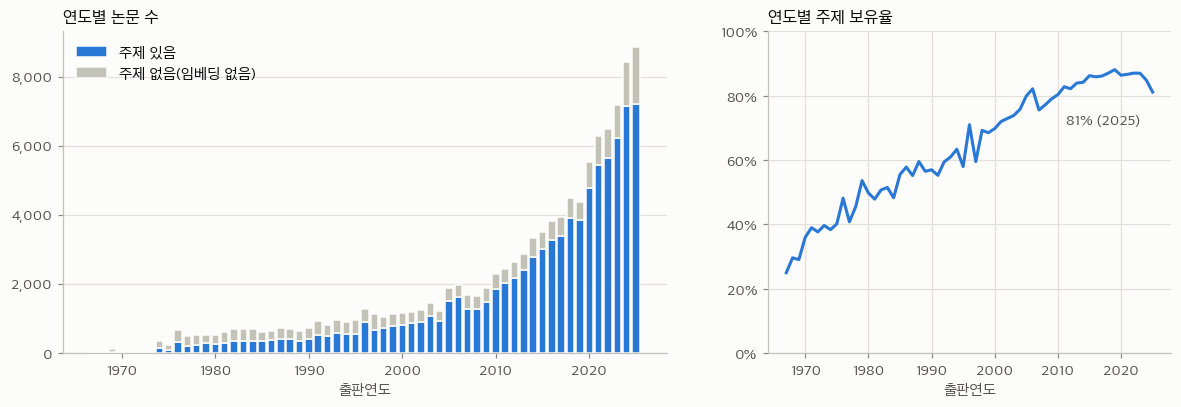

**요약**
- 논문 수는 최근에 몰려 있다. 2020–2025년 논문이 42,831편으로 전체의 **38.3%**다. 2020–24년 논문 수는 2010–14년의 **2.50배**다.
- 주제 보유율은 전체 78.9%지만 **시기에 따라 크게 다르다.** 1975–79년 47%, 1995–99년 66%, 2015–19년 87%로 최근으로 올수록 높아지고, 2025년은 81%로 다시 낮다.
- 따라서 주제를 쓰는 분석(F2, F3, F5, F6)은 **오래된 시기일수록 표본이 덜 대표적**이다. 기간 간 비교에서 이 차이를 변화로 오독하지 않도록 주의해야 한다.

In [4]:
yr = F1.groupby("year").agg(n=("pid", "size"), topic=("has_topic", "sum")); yr["rate"] = yr.topic / yr.n
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1.5, 1]})
ax[0].bar(yr.index, yr.topic, width=0.8, color=C["blue"], label="주제 있음", **BAR)
ax[0].bar(yr.index, yr.n - yr.topic, bottom=yr.topic, width=0.8, color=C["gray"], label="주제 없음(임베딩 없음)", **BAR)
ax[0].set_title("연도별 논문 수"); ax[0].yaxis.set_major_formatter(comma); ax[0].grid(axis="x", visible=False)
ax[0].legend(loc="upper left"); ax[0].set_xlabel("출판연도")
ax[1].plot(yr.index, yr.rate, color=C["blue"]); ax[1].set_ylim(0, 1); ax[1].yaxis.set_major_formatter(pct0)
ax[1].set_title("연도별 주제 보유율"); ax[1].set_xlabel("출판연도")
ax[1].annotate(f"{yr.rate[2025]:.0%} (2025)", (2025, yr.rate[2025]), xytext=(-8, -22), textcoords="offset points", ha="right", color=C["ink2"])
save(fig, "F1_01_연도별_논문수_주제보유율")

p5 = F1.assign(p=F1.year // 5 * 5).groupby("p").agg(논문수=("pid", "size"), 주제보유율=("has_topic", "mean"))
n2020 = int((F1.year >= 2020).sum()); cov = F1.has_topic.mean()
grow = yr.n.loc[2020:2024].sum() / yr.n.loc[2010:2014].sum()
check("2.1", "F1의 연도 범위는 1967–2025이고 in_sample은 전부 True다", (F1.year.min(), F1.year.max()) == (1967, 2025) and F1.in_sample.all(), (F1.year.min(), F1.year.max()))
check("2.1", "주제 보유율은 전체 78.9%다", round(cov, 3) == 0.789, f"{cov:.4f}")
check("2.1", "5년 구간 주제 보유율은 1965–69부터 2015–19까지 단조 증가한다", p5.주제보유율.loc[1965:2015].is_monotonic_increasing, p5.주제보유율.round(3).to_dict())
check("2.1", "2020–24년 논문 수는 2010–14년의 2.5배다", round(grow, 1) == 2.5, f"{grow:.3f}")
check("2.1", "2020년 이후 논문이 전체의 3분의 1 이상이다", n2020 / len(F1) > 1 / 3, f"{n2020/len(F1):.3f}")
md(f"""**요약**
- 논문 수는 최근에 몰려 있다. 2020–2025년 논문이 {n2020:,}편으로 전체의 **{n2020/len(F1):.1%}**다. 2020–24년 논문 수는 2010–14년의 **{grow:.2f}배**다.
- 주제 보유율은 전체 {cov:.1%}지만 **시기에 따라 크게 다르다.** 1975–79년 {p5.주제보유율[1975]:.0%}, 1995–99년 {p5.주제보유율[1995]:.0%}, 2015–19년 {p5.주제보유율[2015]:.0%}로 최근으로 올수록 높아지고, 2025년은 {yr.rate[2025]:.0%}로 다시 낮다.
- 따라서 주제를 쓰는 분석(F2, F3, F5, F6)은 **오래된 시기일수록 표본이 덜 대표적**이다. 기간 간 비교에서 이 차이를 변화로 오독하지 않도록 주의해야 한다.""")

### 2.2 저널 구성: 규모, 등장 시점, 고정 저널

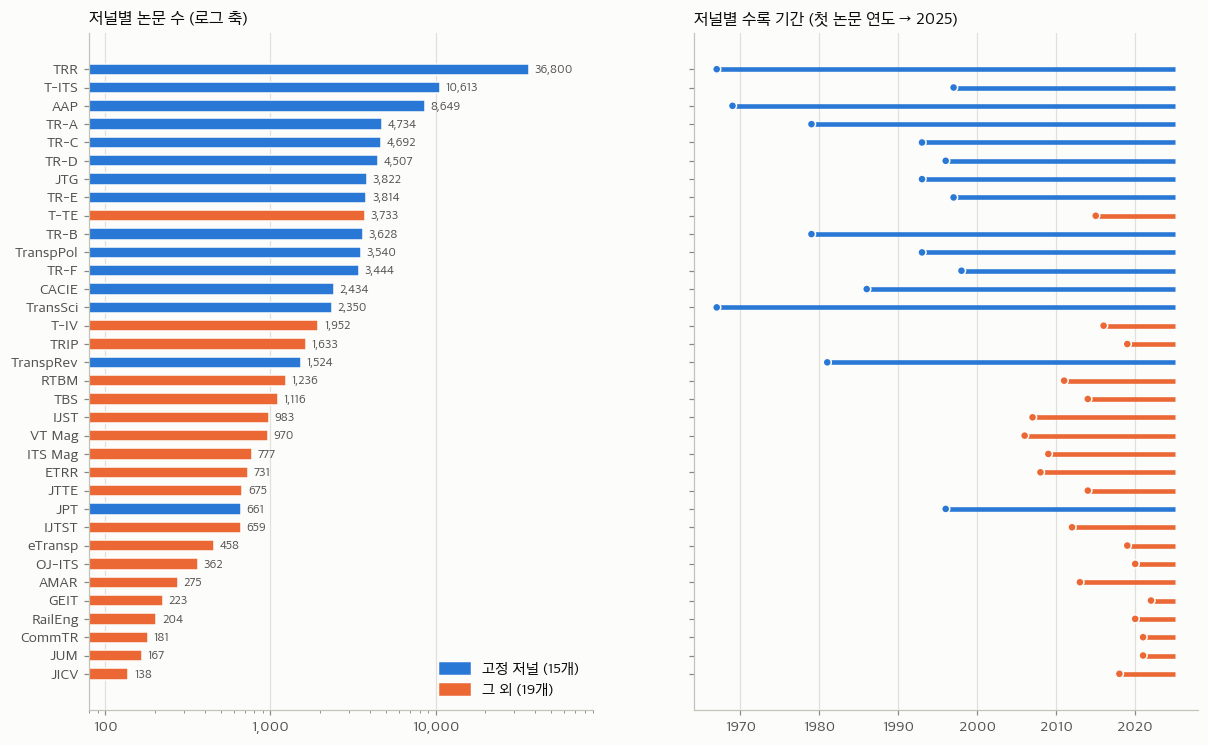

**요약**
- 저널 34개 중 **TRR이 36,800편(32.9%)**으로 압도적으로 크다. 그다음은 T-ITS 10,613편, AAP 8,649편이다. 가장 작은 저널은 JICV 138편이다.
- 저널이 한꺼번에 들어온 것이 아니다. **15개 저널은 첫 논문이 2010년 이후**이고, 이들은 모두 고정 저널이 아니다. 최근 논문에는 과거에 없던 저널이 섞여 있다는 뜻이다.
- 고정 저널 15개(파란색)는 논문의 85.3%를 차지한다.

In [5]:
vn = F1.groupby("venue_short").agg(n=("pid", "size"), first=("year", "min"), last=("year", "max"), fixed=("fixed_venue", "first"),
                                    topic=("has_topic", "mean")).sort_values("n")
col = np.where(vn.fixed, C["blue"], C["orange"])
fig, ax = plt.subplots(1, 2, figsize=(13, 8), sharey=True)
ax[0].barh(vn.index, vn.n, color=col, height=0.62, **BAR); ax[0].set_xscale("log"); ax[0].xaxis.set_major_formatter(comma)
ax[0].set_title("저널별 논문 수 (로그 축)"); ax[0].grid(axis="y", visible=False)
for y, (v, n) in enumerate(vn.n.items()): ax[0].text(n * 1.08, y, f"{n:,}", va="center", fontsize=8, color=C["ink2"])
ax[0].set_xlim(80, 90000)
ax[1].hlines(vn.index, vn["first"], vn["last"], color=col, linewidth=3)
ax[1].scatter(vn["first"], vn.index, color=col, s=28, zorder=3, edgecolor=C["surface"], linewidth=1)
ax[1].set_title("저널별 수록 기간 (첫 논문 연도 → 2025)"); ax[1].grid(axis="y", visible=False)
h = [mpl.patches.Patch(color=C["blue"], label="고정 저널 (15개)"), mpl.patches.Patch(color=C["orange"], label="그 외 (19개)")]
ax[0].legend(handles=h, loc="lower right")
save(fig, "F1_02_저널별_논문수_수록기간")

# fixed_venue 정의 재계산: 2000-04, 05-09, 10-14, 15-19, 2020-25 모든 구간에서 50편 이상
npp = F1[F1.year >= 2000].assign(p=lambda d: np.minimum(d.year // 5 * 5, 2020)).groupby(["venue_short", "p"]).size().unstack(fill_value=0)
FIX = set(npp.index[(npp >= 50).all(axis=1)])
late = vn[vn["first"] >= 2010]
check("2.2", "저널은 34개이고 고정 저널은 15개다", (F1.venue_short.nunique(), vn.fixed.sum()) == (34, 15), (F1.venue_short.nunique(), int(vn.fixed.sum())))
check("2.2", "fixed_venue는 '2000년 이후 5개 구간 모두 50편 이상' 정의로 재계산한 결과와 같다", FIX == set(vn.index[vn.fixed]), sorted(FIX))
check("2.2", "첫 논문이 2010년 이후인 저널은 15개이고 모두 고정 저널이 아니다", len(late) == 15 and not late.fixed.any(), len(late))
check("2.2", "TRR이 단일 저널로 가장 크다(전체의 약 33%)", vn.n.idxmax() == "TRR" and round(vn.n.max() / len(F1), 2) == 0.33, f"{vn.n.max()/len(F1):.3f}")
md(f"""**요약**
- 저널 34개 중 **TRR이 {vn.n['TRR']:,}편({vn.n['TRR']/len(F1):.1%})**으로 압도적으로 크다. 그다음은 T-ITS {vn.n['T-ITS']:,}편, AAP {vn.n['AAP']:,}편이다. 가장 작은 저널은 {vn.index[0]} {vn.n.iloc[0]:,}편이다.
- 저널이 한꺼번에 들어온 것이 아니다. **{len(late)}개 저널은 첫 논문이 2010년 이후**이고, 이들은 모두 고정 저널이 아니다. 최근 논문에는 과거에 없던 저널이 섞여 있다는 뜻이다.
- 고정 저널 15개(파란색)는 논문의 {F1.fixed_venue.mean():.1%}를 차지한다.""")

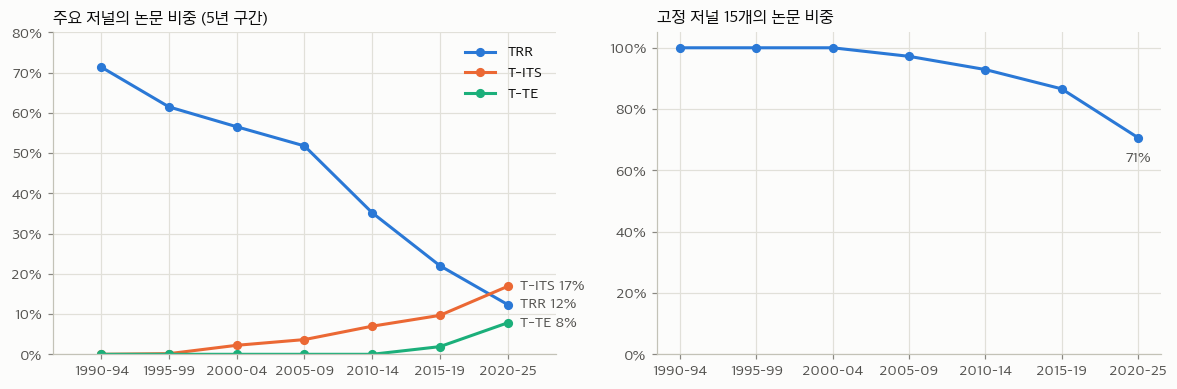

**요약**
- **저널 구성이 시기마다 다르다.** TRR 비중은 1990–94년 71%에서 2020–25년 12%로 줄었고, T-ITS는 2020–25년 17%, T-TE는 8%로 올라왔다.
- 고정 저널 비중은 2000–04년 100%에서 2020–25년 71%로 떨어졌다. 2020년대 논문 열 편 중 세 편은 2000년대 초에는 없던(또는 50편 미만이던) 저널에서 나온다.
- 그래서 기간 간 주제 비중 변화에는 **저널 구성 변화가 섞인다.** 주제 변화 분석은 고정 저널만으로 다시 돌려 보거나 저널 내부 변화로 분해해서 봐야 한다.

In [6]:
F1["p5"] = np.minimum(F1.year // 5 * 5, 2020)
sh = F1[F1.year >= 1990].groupby("p5").venue_short.value_counts(normalize=True).unstack(fill_value=0)
fx = F1[F1.year >= 1990].groupby("p5").fixed_venue.mean()
xl = [f"{p}–{str(p+4)[2:]}" if p < 2020 else "2020–25" for p in sh.index]
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for v, c in zip(["TRR", "T-ITS", "T-TE"], [C["blue"], C["orange"], C["aqua"]]):
    ax[0].plot(xl, sh[v], color=c, marker="o", markersize=5, label=v)
    ax[0].annotate(f"{v} {sh[v].iloc[-1]:.0%}", (len(xl) - 1, sh[v].iloc[-1]), xytext=(8, 0), textcoords="offset points", va="center", color=C["ink2"])
ax[0].set_ylim(0, .8); ax[0].yaxis.set_major_formatter(pct0); ax[0].set_title("주요 저널의 논문 비중 (5년 구간)"); ax[0].legend(loc="upper right"); ax[0].margins(x=.12)
ax[1].plot(xl, fx, color=C["blue"], marker="o", markersize=5); ax[1].set_ylim(0, 1.05); ax[1].yaxis.set_major_formatter(pct0)
ax[1].set_title("고정 저널 15개의 논문 비중"); ax[1].annotate(f"{fx.iloc[-1]:.0%}", (len(xl) - 1, fx.iloc[-1]), xytext=(0, -16), textcoords="offset points", ha="center", color=C["ink2"])
save(fig, "F1_03_저널비중_추이")
check("2.2", "TRR 비중은 1990–94년 71%에서 2020–25년 12%로 줄었다", (round(sh.TRR[1990], 2), round(sh.TRR[2020], 2)) == (0.71, 0.12), (round(sh.TRR[1990], 3), round(sh.TRR[2020], 3)))
check("2.2", "고정 저널 비중은 2000–04년 100%에서 2020–25년 71%로 줄었다", (round(fx[2000], 2), round(fx[2020], 2)) == (1.0, 0.71), (round(fx[2000], 3), round(fx[2020], 3)))
md(f"""**요약**
- **저널 구성이 시기마다 다르다.** TRR 비중은 1990–94년 {sh.TRR[1990]:.0%}에서 2020–25년 {sh.TRR[2020]:.0%}로 줄었고, T-ITS는 2020–25년 {sh['T-ITS'][2020]:.0%}, T-TE는 {sh['T-TE'][2020]:.0%}로 올라왔다.
- 고정 저널 비중은 2000–04년 {fx[2000]:.0%}에서 2020–25년 {fx[2020]:.0%}로 떨어졌다. 2020년대 논문 열 편 중 세 편은 2000년대 초에는 없던(또는 50편 미만이던) 저널에서 나온다.
- 그래서 기간 간 주제 비중 변화에는 **저널 구성 변화가 섞인다.** 주제 변화 분석은 고정 저널만으로 다시 돌려 보거나 저널 내부 변화로 분해해서 봐야 한다.""")

### 2.3 팀 규모와 인용 수

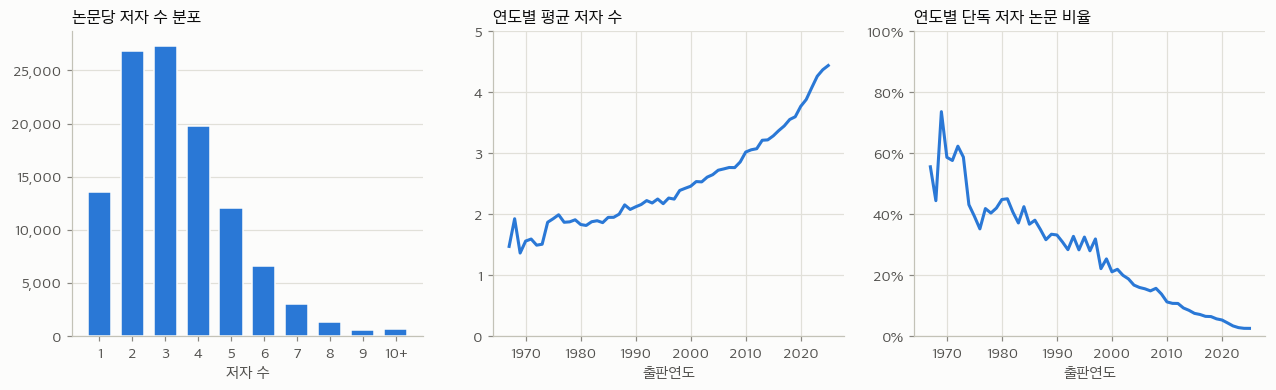

**요약**
- 저자 수는 중앙값 3명, 평균 3.34명이고 최대 43명까지 오른쪽으로 긴 분포다. 단독 저자 논문은 12.1%다.
- 팀이 계속 커졌다. 평균 저자 수는 2000–04년 2.56명에서 2020–25년 4.17명이 됐고, 단독 저자 비율은 1990년 33%에서 2024년 3%로 줄었다.
- 분수 가중치 `w`는 저자 수에 반비례하므로, **최근 저자일수록 같은 논문 수에서도 질량이 작게 잡힌다.** 질량을 기간 간에 직접 비교할 때 유의해야 한다.

In [7]:
na = F1.n_authors.clip(upper=10).value_counts().sort_index()
ty = F1.groupby("year").agg(team=("n_authors", "mean"), solo=("is_solo", "mean"))
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].bar([str(i) if i < 10 else "10+" for i in na.index], na.values, color=C["blue"], width=0.7, **BAR)
ax[0].set_title("논문당 저자 수 분포"); ax[0].yaxis.set_major_formatter(comma); ax[0].grid(axis="x", visible=False); ax[0].set_xlabel("저자 수")
ax[1].plot(ty.index, ty.team, color=C["blue"]); ax[1].set_title("연도별 평균 저자 수"); ax[1].set_ylim(0, 5); ax[1].set_xlabel("출판연도")
ax[2].plot(ty.index, ty.solo, color=C["blue"]); ax[2].set_title("연도별 단독 저자 논문 비율"); ax[2].set_ylim(0, 1); ax[2].yaxis.set_major_formatter(pct0); ax[2].set_xlabel("출판연도")
save(fig, "F1_04_팀규모")
t5 = F1.groupby("p5").n_authors.mean()
check("2.3", "is_solo는 n_authors==1과 완전히 같다", ((F1.n_authors == 1) == (F1.is_solo == 1)).all())
check("2.3", "저자 수 중앙값은 3명, 최댓값은 43명이다", (F1.n_authors.median(), F1.n_authors.max()) == (3, 43), (F1.n_authors.median(), F1.n_authors.max()))
md(f"""**요약**
- 저자 수는 중앙값 {F1.n_authors.median():.0f}명, 평균 {F1.n_authors.mean():.2f}명이고 최대 {F1.n_authors.max()}명까지 오른쪽으로 긴 분포다. 단독 저자 논문은 {F1.is_solo.mean():.1%}다.
- 팀이 계속 커졌다. 평균 저자 수는 2000–04년 {t5[2000]:.2f}명에서 2020–25년 {t5[2020]:.2f}명이 됐고, 단독 저자 비율은 1990년 {ty.solo[1990]:.0%}에서 2024년 {ty.solo[2024]:.0%}로 줄었다.
- 분수 가중치 `w`는 저자 수에 반비례하므로, **최근 저자일수록 같은 논문 수에서도 질량이 작게 잡힌다.** 질량을 기간 간에 직접 비교할 때 유의해야 한다.""")

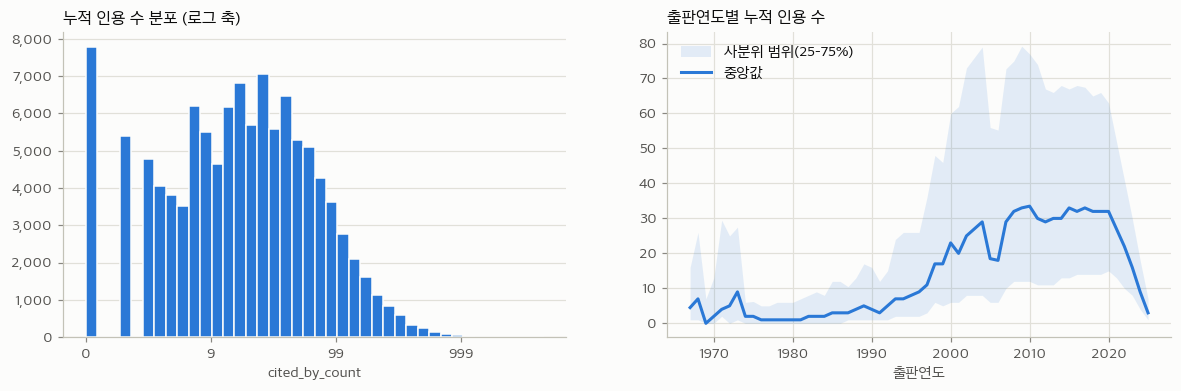

**요약**
- 인용 수는 매우 치우친 분포다. 중앙값 17, 평균 40.0, 상위 10% 기준 95, 상위 1% 기준 338, 최대 4,582이다. 0회 인용 논문이 7.0%이고, 상위 1% 논문이 전체 인용의 14.9%를 가져간다.
- `cited_by_count`는 수집 시점의 누적값이라 **출판연도에 강하게 좌우된다.** 중앙값이 2015년 33, 2020년 32, 2023년 16, 2025년 3다. 1990년 이전 논문도 중앙값이 낮다(1980년 1).
- 그래서 연도가 다른 논문의 인용 수를 그대로 비교할 수 없다. 쓰려면 같은 연도(가능하면 같은 저널) 안의 순위로 바꿔야 한다.

In [8]:
cy = F1.groupby("year").cited_by_count.quantile([.25, .5, .75]).unstack()
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
ax[0].hist(np.log10(F1.cited_by_count + 1), bins=40, color=C["blue"], **BAR)
ax[0].set_xticks([0, 1, 2, 3]); ax[0].set_xticklabels(["0", "9", "99", "999"]); ax[0].yaxis.set_major_formatter(comma)
ax[0].set_title("누적 인용 수 분포 (로그 축)"); ax[0].set_xlabel("cited_by_count"); ax[0].grid(axis="x", visible=False)
ax[1].fill_between(cy.index, cy[.25], cy[.75], color=C["blue"], alpha=.12, linewidth=0, label="사분위 범위(25–75%)")
ax[1].plot(cy.index, cy[.5], color=C["blue"], label="중앙값"); ax[1].set_title("출판연도별 누적 인용 수"); ax[1].legend(loc="upper left"); ax[1].set_xlabel("출판연도")
save(fig, "F1_05_인용수")
q = F1.cited_by_count.quantile([.5, .9, .99]); top1 = F1.cited_by_count.nlargest(len(F1) // 100).sum() / F1.cited_by_count.sum()
check("2.3", "인용 수 중앙값은 17, 최댓값은 4,582다", (q[.5], F1.cited_by_count.max()) == (17, 4582), (q[.5], F1.cited_by_count.max()))
check("2.3", "연도별 인용 중앙값은 2023→2024→2025로 갈수록 줄어든다(누적값의 나이 효과)", cy[.5][2023] > cy[.5][2024] > cy[.5][2025], cy[.5].loc[2021:2025].to_dict())
md(f"""**요약**
- 인용 수는 매우 치우친 분포다. 중앙값 {q[.5]:.0f}, 평균 {F1.cited_by_count.mean():.1f}, 상위 10% 기준 {q[.9]:.0f}, 상위 1% 기준 {q[.99]:.0f}, 최대 {F1.cited_by_count.max():,}이다. 0회 인용 논문이 {(F1.cited_by_count==0).mean():.1%}이고, 상위 1% 논문이 전체 인용의 {top1:.1%}를 가져간다.
- `cited_by_count`는 수집 시점의 누적값이라 **출판연도에 강하게 좌우된다.** 중앙값이 2015년 {cy[.5][2015]:.0f}, 2020년 {cy[.5][2020]:.0f}, 2023년 {cy[.5][2023]:.0f}, 2025년 {cy[.5][2025]:.0f}다. 1990년 이전 논문도 중앙값이 낮다(1980년 {cy[.5][1980]:.0f}).
- 그래서 연도가 다른 논문의 인용 수를 그대로 비교할 수 없다. 쓰려면 같은 연도(가능하면 같은 저널) 안의 순위로 바꿔야 한다.""")

### 2.4 결측과 품질: 주제 없는 논문, DOI 결측, 중복 제목

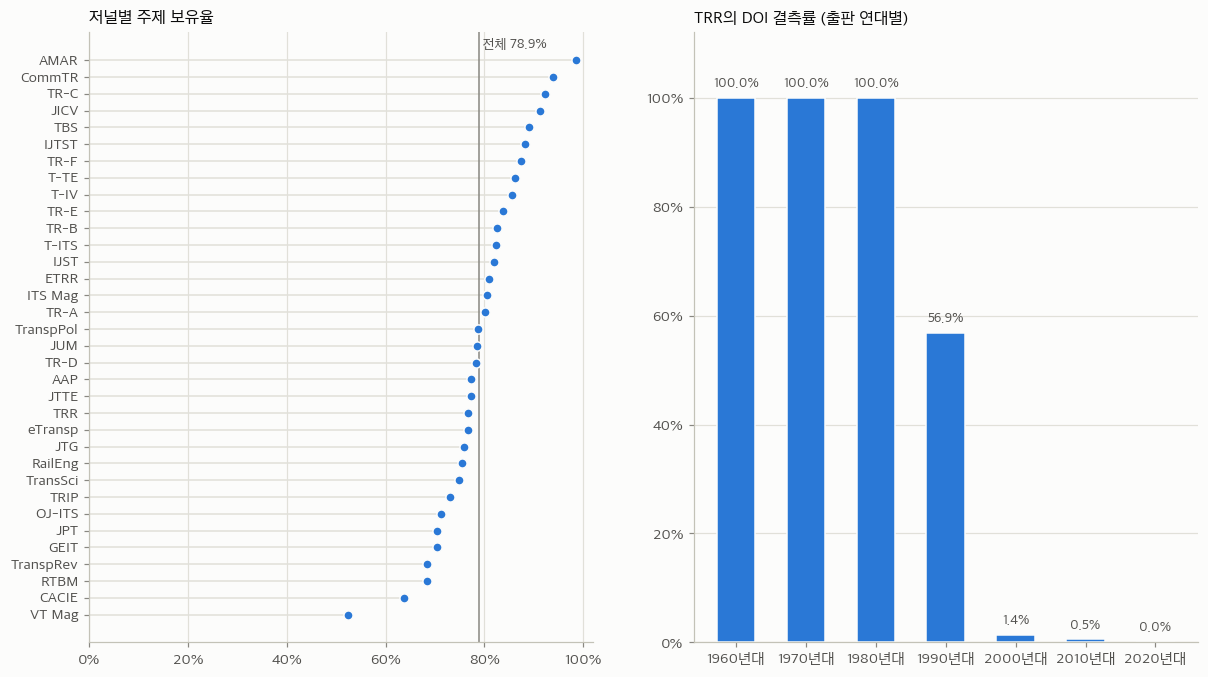

,평균저자수,인용중앙값,연도중앙값
has_topic,,,
False,2.40,9.0,2008.0
True,3.59,19.0,2018.0


,같은 제목의 행 수
title,
Bibliographic Section,35
TGRG page,17
Books of Interest,13
Book of Interest,11
TGSG: The Transport Geography Study Group of the Institute of British Geographers,4
Advances in Automotive Electronics [Automotive Electronics],3


**요약**
- **주제 없는 논문은 무작위로 빠진 것이 아니다.** 주제 있는 논문은 평균 저자 수 3.59명·인용 중앙값 19회·연도 중앙값 2018년이고, 주제 없는 논문은 각각 2.40명·9회·2008년이다. 저널별 보유율도 VT Mag 52%부터 AMAR 99%까지 벌어진다.
- DOI 결측 11,796건(10.6%) 중 96.2%가 TRR이고, TRR의 1990년 이전 논문 7,493편은 2편을 빼고 모두 DOI가 없다. DOI가 없는 논문은 주제 보유율도 55%로 낮다.
- `in_sample`로 중복 제목과 비연구 항목을 걸렀다고 하지만 **완전히 걸러지지는 않았다.** 같은 제목이 459행 남아 있고, 그중 상위는 "Bibliographic Section"(35행), "TGRG page"(17행) 같은 비연구 항목이다. 규모가 전체의 0.41%라 결과를 바꿀 정도는 아니지만, 이 중 63%에는 주제가 붙어 있어 주제 분석에도 들어간다.

In [9]:
tv = F1.groupby("venue_short").has_topic.mean().sort_values()
dv = F1.assign(dec=F1.year // 10 * 10).groupby(["venue_short", "dec"]).doi_norm.apply(lambda s: s.isna().mean()).unstack()
fig, ax = plt.subplots(1, 2, figsize=(13, 7.2), gridspec_kw={"width_ratios": [1, 1]})
ax[0].hlines(tv.index, 0, tv.values, color=C["grid"], linewidth=1)
ax[0].scatter(tv.values, tv.index, color=C["blue"], s=36, zorder=3, edgecolor=C["surface"], linewidth=1)
ax[0].axvline(F1.has_topic.mean(), color=C["muted"], linewidth=1); ax[0].text(F1.has_topic.mean(), len(tv) - .3, f" 전체 {F1.has_topic.mean():.1%}", color=C["ink2"], fontsize=9)
ax[0].set_xlim(0, 1.02); ax[0].xaxis.set_major_formatter(pct0); ax[0].set_title("저널별 주제 보유율"); ax[0].grid(axis="y", visible=False)
trr = dv.loc["TRR"].dropna()
ax[1].bar([f"{int(d)}년대" for d in trr.index], trr.values, color=C["blue"], width=0.55, **BAR)
for i, v in enumerate(trr.values): ax[1].text(i, v + .02, f"{v:.1%}", ha="center", color=C["ink2"], fontsize=9)
ax[1].set_ylim(0, 1.12); ax[1].yaxis.set_major_formatter(pct0); ax[1].set_title("TRR의 DOI 결측률 (출판 연대별)"); ax[1].grid(axis="x", visible=False)
save(fig, "F1_06_주제보유율_DOI결측")

trr_pre90 = F1[(F1.venue_short == "TRR") & (F1.year < 1990)].doi_norm.isna().mean()
_pre = F1[(F1.venue_short == "TRR") & (F1.year < 1990)]; n_pre90, n_pre90_doi = len(_pre), int(_pre.doi_norm.notna().sum())
dna = F1.doi_norm.isna(); trr_share = (dna & (F1.venue_short == "TRR")).sum() / dna.sum()
ct = pd.crosstab(dna.map({True: "DOI 없음", False: "DOI 있음"}), F1.has_topic.map({True: "주제 있음", False: "주제 없음"}), normalize="index")
tt = F1.groupby("has_topic").agg(평균저자수=("n_authors", "mean"), 인용중앙값=("cited_by_count", "median"), 연도중앙값=("year", "median"))
dup = F1[F1.title.duplicated(keep=False)]; topdup = F1.title.value_counts().head(6)
check("2.4", "DOI 결측은 11,796건(10.6%)이고 DOI가 있는 논문끼리는 중복이 없다", dna.sum() == 11796 and not F1.doi_norm.dropna().duplicated().any(), int(dna.sum()))
check("2.4", "TRR의 1990년 이전 논문은 99% 이상 DOI가 없다", trr_pre90 > .99, f"{trr_pre90:.4f}")
check("2.4", "DOI 결측의 95% 이상이 TRR이다", trr_share > .95, f"{trr_share:.3f}")
check("2.4", "DOI 없는 논문은 주제 보유율이 55%로, DOI 있는 논문(82%)보다 낮다", (round(ct.loc['DOI 없음', '주제 있음'], 2), round(ct.loc['DOI 있음', '주제 있음'], 2)) == (0.55, 0.82), ct.round(3).to_dict())
check("2.4", "제목이 같은 논문이 459행(고유 제목 기준 중복 266건) 남아 있다", (len(dup), int(F1.title.duplicated().sum())) == (459, 266), (len(dup), int(F1.title.duplicated().sum())))
display(tt.round(2)); display(topdup.to_frame("같은 제목의 행 수"))
md(f"""**요약**
- **주제 없는 논문은 무작위로 빠진 것이 아니다.** 주제 있는 논문은 평균 저자 수 {tt.평균저자수[True]:.2f}명·인용 중앙값 {tt.인용중앙값[True]:.0f}회·연도 중앙값 {tt.연도중앙값[True]:.0f}년이고, 주제 없는 논문은 각각 {tt.평균저자수[False]:.2f}명·{tt.인용중앙값[False]:.0f}회·{tt.연도중앙값[False]:.0f}년이다. 저널별 보유율도 {tv.index[0]} {tv.iloc[0]:.0%}부터 {tv.index[-1]} {tv.iloc[-1]:.0%}까지 벌어진다.
- DOI 결측 {dna.sum():,}건({dna.mean():.1%}) 중 {trr_share:.1%}가 TRR이고, TRR의 1990년 이전 논문 {n_pre90:,}편은 {n_pre90_doi}편을 빼고 모두 DOI가 없다. DOI가 없는 논문은 주제 보유율도 {ct.loc['DOI 없음','주제 있음']:.0%}로 낮다.
- `in_sample`로 중복 제목과 비연구 항목을 걸렀다고 하지만 **완전히 걸러지지는 않았다.** 같은 제목이 {len(dup):,}행 남아 있고, 그중 상위는 "{topdup.index[0]}"({topdup.iloc[0]}행), "{topdup.index[1]}"({topdup.iloc[1]}행) 같은 비연구 항목이다. 규모가 전체의 {len(dup)/len(F1):.2%}라 결과를 바꿀 정도는 아니지만, 이 중 {dup.has_topic.mean():.0%}에는 주제가 붙어 있어 주제 분석에도 들어간다.""")

## 3. F6 — 주제표 (150개 주제)와 F1의 주제 분포

### 3.1 주제 크기와 신생·쇠퇴 지정

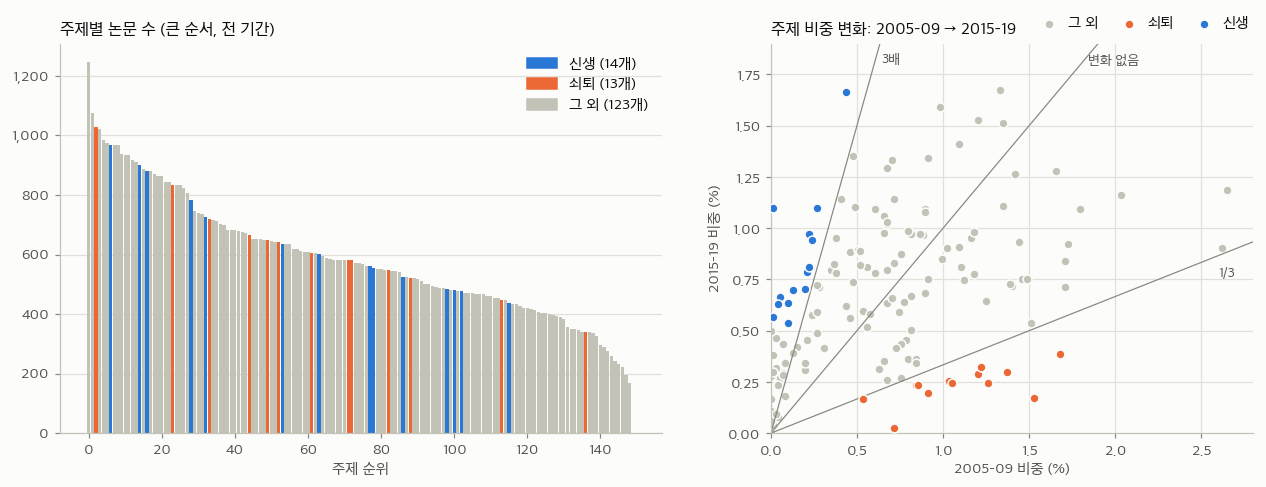

**요약**
- 주제 150개의 크기는 비교적 고르다. 가장 큰 주제가 1,246편, 18번을 뺀 가장 작은 주제가 169편이고 중앙값은 570편이다. 한 주제가 전체의 1.4%를 넘지 않는다.
- **주제 18번은 사실상 빈 주제다.** 논문이 1편(1974년)뿐이라 F6의 세 기간 비중이 모두 0이고 `top_words`도 비어 있다. 실질 주제 수는 149개다.
- F6의 비중과 신생·쇠퇴 지정은 F2에서 다시 계산한 값과 정확히 같다. `share_2025`는 2025년 한 해가 아니라 2020–2025년 전체의 비중이다.
- 신생·쇠퇴 지정은 **2005–09와 2015–19 두 시점만** 쓴다. 신생 14개 중 6개는 2005–09년 비중이 0.1% 미만이었다(오른쪽 그림에서 세로축에 붙은 파란 점들). 이런 주제는 출발점이 0에 가까워 배수가 수십 배로 나오므로, 배수보다 **비중의 절대 증가폭**으로 읽어야 한다.

In [10]:
F6["cat"] = np.where(F6.emerging, "신생", np.where(F6.declining, "쇠퇴", "그 외"))
F6["label"] = F6.topic150.astype(str) + " · " + F6.top_words.fillna("(단어 없음)").map(lambda s: ", ".join(s.split(", ")[:3]))
CATC = {"신생": C["blue"], "쇠퇴": C["orange"], "그 외": C["gray"]}
tc = F1.topic150.dropna().astype(int).value_counts().reindex(range(K), fill_value=0)
od = tc.sort_values(ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1.25, 1]})
ax[0].bar(range(K), od.values, color=[CATC[F6.cat[k]] for k in od.index], width=0.9)
ax[0].set_title("주제별 논문 수 (큰 순서, 전 기간)"); ax[0].set_xlabel("주제 순위"); ax[0].yaxis.set_major_formatter(comma); ax[0].grid(axis="x", visible=False)
ax[0].legend(handles=[mpl.patches.Patch(color=c, label=f"{k} ({(F6.cat==k).sum()}개)") for k, c in CATC.items()], loc="upper right")
for k in ["그 외", "쇠퇴", "신생"]:
    g = F6[F6.cat == k]; ax[1].scatter(g.share_0509 * 100, g.share_1519 * 100, s=34, color=CATC[k], edgecolor=C["surface"], linewidth=1, label=k, zorder=3 if k != "그 외" else 2)
xx = np.linspace(0, 2.8, 50)
for sl, tx in [(3, "3배"), (1, "변화 없음"), (1 / 3, "1/3")]:
    ax[1].plot(xx, xx * sl, color=C["muted"], linewidth=0.8)
ax[1].text(.64, 1.8, "3배", color=C["ink2"], fontsize=9); ax[1].text(1.84, 1.8, "변화 없음", color=C["ink2"], fontsize=9); ax[1].text(2.6, .76, "1/3", color=C["ink2"], fontsize=9)
ax[1].set_xlim(0, 2.8); ax[1].set_ylim(0, 1.9); ax[1].set_xlabel("2005–09 비중 (%)"); ax[1].set_ylabel("2015–19 비중 (%)")
ax[1].set_title("주제 비중 변화: 2005–09 → 2015–19"); ax[1].legend(loc="lower right", ncol=3, bbox_to_anchor=(1.02, 1.0), columnspacing=1, handletextpad=.2)
save(fig, "F6_01_주제크기_비중변화")

# --- F6 값의 재계산 검증 (F2에서 논문 단위로 중복 제거 후 기간별 주제 비중) ---
def share(y0, y1):
    s = F2[F2.year.between(y0, y1)].drop_duplicates("pid"); return np.bincount(s.topic150, minlength=K) / len(s)
s0, s1, s2 = share(2005, 2009), share(2015, 2019), share(2020, 2025)
ratio = (s1 + 1e-4) / (s0 + 1e-4); EM = (ratio >= 3) & (s1 >= .005); DEC = (ratio <= 1 / 3) & (s0 >= .005)
check("3.1", "F6의 share_0509, share_1519, share_2025는 F2에서 재계산한 값과 같다(share_2025는 2020–2025 전체)", np.allclose(s0, F6.share_0509) and np.allclose(s1, F6.share_1519) and np.allclose(s2, F6.share_2025))
check("3.1", "emerging, declining 지정은 정의(3배 이상·0.5% 이상 / 3분의 1 이하·과거 0.5% 이상)로 재계산한 결과와 같다", (EM == F6.emerging.values).all() and (DEC == F6.declining.values).all())
check("3.1", "신생 14개, 쇠퇴 13개이고 둘 다인 주제는 없다", (F6.emerging.sum(), F6.declining.sum(), (F6.emerging & F6.declining).sum()) == (14, 13, 0), (int(F6.emerging.sum()), int(F6.declining.sum())))
t18 = int(tc[18]); t18y = F1.loc[F1.topic150 == 18, "year"].tolist()
check("3.1", "주제 18번은 논문이 1편(1974년)뿐이라 세 기간 비중이 모두 0이고 top_words가 비어 있다", t18 == 1 and t18y == [1974] and F6.loc[18, ["share_0509", "share_1519", "share_2025"]].sum() == 0 and pd.isna(F6.top_words[18]), (t18, t18y))
big, small = od.iloc[0], od[od > 1].iloc[-1]
n_tiny = int((F6.share_0509[F6.emerging] < .001).sum())
check("3.1", "주제별 논문 수는 18번을 빼면 최소 169편, 최대 1,246편이다", (int(big), int(small)) == (1246, 169), (int(big), int(small)))
check("3.1", "신생 14개 주제 중 6개는 2005–09 비중이 0.1% 미만이었다", n_tiny == 6, n_tiny)
md(f"""**요약**
- 주제 150개의 크기는 비교적 고르다. 가장 큰 주제가 {big:,}편, 18번을 뺀 가장 작은 주제가 {small:,}편이고 중앙값은 {od.median():.0f}편이다. 한 주제가 전체의 {big/tc.sum():.1%}를 넘지 않는다.
- **주제 18번은 사실상 빈 주제다.** 논문이 {t18}편(1974년)뿐이라 F6의 세 기간 비중이 모두 0이고 `top_words`도 비어 있다. 실질 주제 수는 149개다.
- F6의 비중과 신생·쇠퇴 지정은 F2에서 다시 계산한 값과 정확히 같다. `share_2025`는 2025년 한 해가 아니라 2020–2025년 전체의 비중이다.
- 신생·쇠퇴 지정은 **2005–09와 2015–19 두 시점만** 쓴다. 신생 14개 중 {n_tiny}개는 2005–09년 비중이 0.1% 미만이었다(오른쪽 그림에서 세로축에 붙은 파란 점들). 이런 주제는 출발점이 0에 가까워 배수가 수십 배로 나오므로, 배수보다 **비중의 절대 증가폭**으로 읽어야 한다.""")

### 3.2 신생·쇠퇴 주제의 세 시점 비중

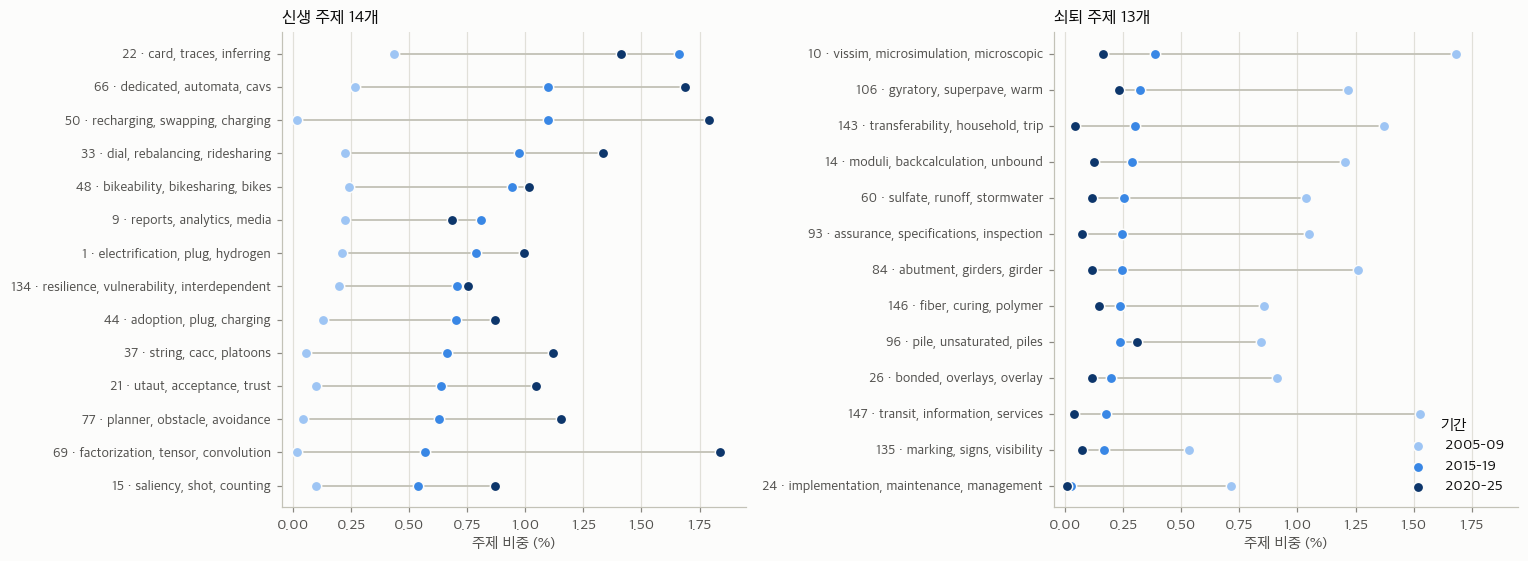

**요약**
- 신생 14개 주제의 합산 비중은 2005–09년 2.2% → 2015–19년 11.8% → 2020–25년 16.6%다. 쇠퇴 13개 주제는 14.2% → 3.1% → 1.5%다.
- 지정에 쓰지 않은 2020–25년에도 방향이 대체로 이어진다. 신생 14개 중 **12개**가 2015–19년보다 더 커졌고, 쇠퇴 13개 중 **12개**가 더 작아졌다. 지정이 한 시점의 우연이 아니라는 근거다.
- 신생 주제는 전기차·충전(1, 44, 50), 자율주행·군집주행(37, 66, 77), 공유 모빌리티(33, 48), 그래프·텐서 기반 예측(69) 등이다. 쇠퇴 주제는 포장·구조·재료(14, 26, 84, 106, 146) 같은 토목 주제가 많다.
- **쇠퇴 주제는 사실상 TRR의 주제다.** 쇠퇴 13개 주제 논문의 93.8%가 TRR에 실렸고(주제별로 최소 79%), 주제 있는 전체 논문에서는 TRR이 32.0%, 신생 주제에서는 12.6%다. 2.2절에서 본 TRR 비중 감소와 겹치므로, 이 주제들의 "쇠퇴"가 주제 자체의 쇠퇴인지 TRR 비중이 줄어든 결과인지는 비중만으로는 구분되지 않는다.

In [11]:
def dumbbell(ax, g, title):
    g = g.sort_values("share_1519"); y = np.arange(len(g))
    ax.hlines(y, g[["share_0509", "share_1519", "share_2025"]].min(axis=1) * 100, g[["share_0509", "share_1519", "share_2025"]].max(axis=1) * 100, color=C["gray"], linewidth=1.2)
    for c, lab, col in zip(["share_0509", "share_1519", "share_2025"], ["2005–09", "2015–19", "2020–25"], ORD3):
        ax.scatter(g[c] * 100, y, s=46, color=col, edgecolor=C["surface"], linewidth=1, label=lab, zorder=3)
    ax.set_yticks(y); ax.set_yticklabels(g.label, fontsize=9); ax.set_title(title); ax.set_xlabel("주제 비중 (%)"); ax.grid(axis="y", visible=False); ax.set_xlim(-.05, 1.95)
fig, ax = plt.subplots(1, 2, figsize=(14, 5.2))
dumbbell(ax[0], F6[F6.emerging], "신생 주제 14개"); dumbbell(ax[1], F6[F6.declining], "쇠퇴 주제 13개")
ax[1].legend(loc="lower right", title="기간"); fig.tight_layout()
save(fig, "F6_02_신생쇠퇴_세시점")
em, dc = F6[F6.emerging], F6[F6.declining]
em_up, dc_dn = int((em.share_2025 > em.share_1519).sum()), int((dc.share_2025 < dc.share_1519).sum())
em_tot = em[["share_0509", "share_1519", "share_2025"]].sum(); dc_tot = dc[["share_0509", "share_1519", "share_2025"]].sum()
check("3.2", "신생 14개 주제의 합산 비중은 2.2% → 11.8% → 16.6%로 커졌다", [round(v, 3) for v in em_tot] == [0.022, 0.118, 0.166], em_tot.round(4).to_dict())
check("3.2", "쇠퇴 13개 주제의 합산 비중은 14.2% → 3.1% → 1.5%로 줄었다", [round(v, 3) for v in dc_tot] == [0.142, 0.031, 0.015], dc_tot.round(4).to_dict())
tt_ = F1[F1.has_topic].assign(t=lambda d: d.topic150.astype(int)); is_trr = tt_.venue_short == "TRR"
trr_dc, trr_em, trr_all = is_trr[tt_.t.isin(dc.topic150)].mean(), is_trr[tt_.t.isin(em.topic150)].mean(), is_trr.mean()
trr_dc_min = is_trr[tt_.t.isin(dc.topic150)].groupby(tt_.t).mean().min()
check("3.2", "신생 14개 중 12개는 2020–25년에 더 커졌고, 쇠퇴 13개 중 12개는 더 작아졌다", (em_up, dc_dn) == (12, 12), (em_up, dc_dn))
check("3.2", "쇠퇴 13개 주제 논문의 93.8%가 TRR에 실렸다(주제 있는 전체 논문은 32.0%, 신생 주제는 12.6%)", (round(trr_dc, 3), round(trr_all, 3), round(trr_em, 3)) == (.938, .320, .126), (round(trr_dc, 4), round(trr_all, 4), round(trr_em, 4)))
md(f"""**요약**
- 신생 14개 주제의 합산 비중은 2005–09년 {em_tot.iloc[0]:.1%} → 2015–19년 {em_tot.iloc[1]:.1%} → 2020–25년 {em_tot.iloc[2]:.1%}다. 쇠퇴 13개 주제는 {dc_tot.iloc[0]:.1%} → {dc_tot.iloc[1]:.1%} → {dc_tot.iloc[2]:.1%}다.
- 지정에 쓰지 않은 2020–25년에도 방향이 대체로 이어진다. 신생 14개 중 **{em_up}개**가 2015–19년보다 더 커졌고, 쇠퇴 13개 중 **{dc_dn}개**가 더 작아졌다. 지정이 한 시점의 우연이 아니라는 근거다.
- 신생 주제는 전기차·충전(1, 44, 50), 자율주행·군집주행(37, 66, 77), 공유 모빌리티(33, 48), 그래프·텐서 기반 예측(69) 등이다. 쇠퇴 주제는 포장·구조·재료(14, 26, 84, 106, 146) 같은 토목 주제가 많다.
- **쇠퇴 주제는 사실상 TRR의 주제다.** 쇠퇴 13개 주제 논문의 {trr_dc:.1%}가 TRR에 실렸고(주제별로 최소 {trr_dc_min:.0%}), 주제 있는 전체 논문에서는 TRR이 {trr_all:.1%}, 신생 주제에서는 {trr_em:.1%}다. 2.2절에서 본 TRR 비중 감소와 겹치므로, 이 주제들의 "쇠퇴"가 주제 자체의 쇠퇴인지 TRR 비중이 줄어든 결과인지는 비중만으로는 구분되지 않는다.""")

### 3.3 신생 주제는 어느 저널에 실리는가

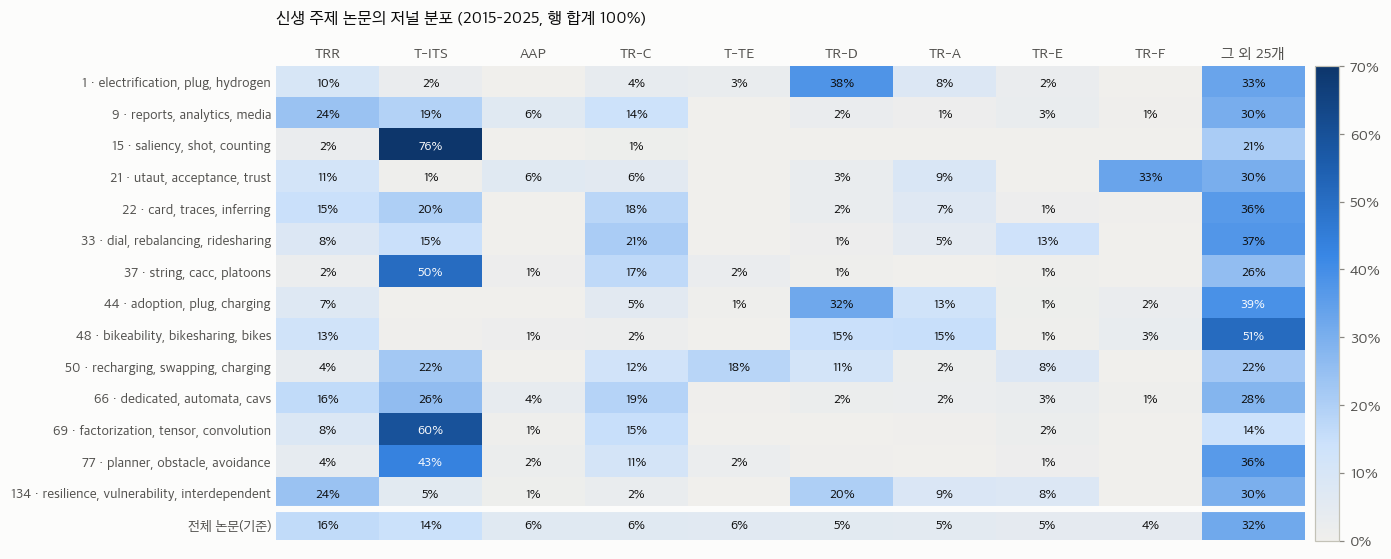

**요약**
- 신생 주제는 저널에 고르게 퍼져 있지 않다. 14개 중 **3개 주제는 한 저널이 절반 이상**을 차지한다(15번→T-ITS 76%, 37번→T-ITS 50%, 69번→T-ITS 60%). 14개 중 7개는 가장 많이 실리는 저널이 T-ITS다. 맨 아래 기준 행(전체 논문)과 비교하면 쏠림이 뚜렷하다.
- 신생 주제 논문 중 고정 저널이 아닌 곳에 실린 비율은 주제에 따라 8%에서 36%까지 다르다(전체 평균 23%).
- 즉 **"어떤 주제를 하느냐"와 "어느 저널에 싣느냐"가 강하게 묶여 있다.** 신규 저자와 지속 저자의 주제 차이를 볼 때 저널을 통제하지 않으면 저널 차이가 주제 차이로 잡힌다.

In [12]:
rec = F1[F1.has_topic & (F1.year >= 2015)].assign(t=lambda d: d.topic150.astype(int))
topv = rec.venue_short.value_counts().head(9).index.tolist()
rec["v"] = np.where(rec.venue_short.isin(topv), rec.venue_short, "그 외 25개")
H = pd.crosstab(rec.t, rec.v, normalize="index").reindex(columns=topv + ["그 외 25개"])
base = rec.v.value_counts(normalize=True).reindex(H.columns)
Hem = H.loc[F6.index[F6.emerging]]; Hem.index = F6.label[Hem.index]
M = pd.concat([Hem, base.to_frame("전체 논문(기준)").T])
fig, ax = plt.subplots(figsize=(12.5, 5.6))
im = ax.imshow(M.values, cmap=SEQ, vmin=0, vmax=.7, aspect="auto")
ax.set_xticks(range(M.shape[1])); ax.set_xticklabels(M.columns); ax.set_yticks(range(len(M))); ax.set_yticklabels(M.index, fontsize=9)
ax.xaxis.tick_top(); ax.grid(False); ax.tick_params(length=0)
for s in ax.spines.values(): s.set_visible(False)
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        v = M.values[i, j]
        if v >= .005: ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=8.5, color="white" if v > .38 else C["ink"])
ax.axhline(len(M) - 1.5, color=C["surface"], linewidth=4)
ax.set_title("신생 주제 논문의 저널 분포 (2015–2025, 행 합계 100%)", pad=28)
fig.colorbar(im, ax=ax, fraction=.025, pad=.01, format=pct0)
save(fig, "F6_03_신생주제_저널분포")
Hfull = pd.crosstab(rec.t, rec.venue_short, normalize="index").loc[F6.index[F6.emerging]]      # 묶지 않은 34개 저널 기준
conc, concv = Hfull.max(axis=1), Hfull.idxmax(axis=1); n_conc = int((conc >= .5).sum()); n_tits = int((concv == "T-ITS").sum()); nonfix = rec.assign(nf=~rec.fixed_venue).groupby("t").nf.mean()
check("3.3", "신생 14개 주제 중 한 저널에 절반 이상이 몰린 주제가 3개이고, 7개 주제는 1위 저널이 T-ITS다", (n_conc, n_tits) == (3, 7), {k: (concv[k], round(v, 2)) for k, v in conc.items()})
md(f"""**요약**
- 신생 주제는 저널에 고르게 퍼져 있지 않다. 14개 중 **{n_conc}개 주제는 한 저널이 절반 이상**을 차지한다({', '.join(f'{k}번→{concv[k]} {v:.0%}' for k, v in conc[conc >= .5].items())}). 14개 중 {n_tits}개는 가장 많이 실리는 저널이 T-ITS다. 맨 아래 기준 행(전체 논문)과 비교하면 쏠림이 뚜렷하다.
- 신생 주제 논문 중 고정 저널이 아닌 곳에 실린 비율은 주제에 따라 {nonfix[F6.index[F6.emerging]].min():.0%}에서 {nonfix[F6.index[F6.emerging]].max():.0%}까지 다르다(전체 평균 {(~rec.fixed_venue).mean():.0%}).
- 즉 **"어떤 주제를 하느냐"와 "어느 저널에 싣느냐"가 강하게 묶여 있다.** 신규 저자와 지속 저자의 주제 차이를 볼 때 저널을 통제하지 않으면 저널 차이가 주제 차이로 잡힌다.""")

### 3.4 `top_words`의 재현성

In [13]:
STOP = set("with from using based study analysis model models approach method methods case data their this that into under over towards toward between during traffic transport transportation".split())
T = F1[F1.has_topic & (F1.year >= 2005)].copy()
T["tk"] = T.title.map(lambda s: set(w for w in re.findall(r"[a-z]{4,}", str(s).lower()) if w not in STOP))
ca, nall = Counter(w for s in T.tk for w in s), len(T)
def words(k):
    g = T[T.topic150 == k]; c = Counter(w for s in g.tk for w in s)
    sc = {w: (v / len(g)) / (ca[w] / nall) for w, v in c.items() if v >= 10}
    return sorted(sc, key=sc.get, reverse=True)[:6]
same_set = sum(set(words(k)) == set(F6.top_words[k].split(", ")) for k in range(K) if isinstance(F6.top_words[k], str))
check("3.4", "top_words는 구축 코드의 방식(2005년 이후 제목 단어의 상대 빈도 상위 6개)으로 재계산하면 149개 주제 모두 같은 단어 집합이 나온다", same_set == 149, f"{same_set}/149")
md(f"""**요약**
- `top_words`는 2005년 이후 논문 제목에서 "그 주제에서의 등장 비율 ÷ 전체에서의 등장 비율"이 큰 단어 6개다. 같은 방식으로 다시 계산하면 **{same_set}/149개 주제에서 같은 단어 집합**이 나온다.
- 이 방식은 희귀하지만 그 주제에 쏠린 단어를 올린다. 그래서 주제의 대표 단어라기보다 **구별 단어**에 가깝다. 주제의 이름은 제목을 직접 읽고 붙여야 한다.""")

**요약**
- `top_words`는 2005년 이후 논문 제목에서 "그 주제에서의 등장 비율 ÷ 전체에서의 등장 비율"이 큰 단어 6개다. 같은 방식으로 다시 계산하면 **149/149개 주제에서 같은 단어 집합**이 나온다.
- 이 방식은 희귀하지만 그 주제에 쏠린 단어를 올린다. 그래서 주제의 대표 단어라기보다 **구별 단어**에 가깝다. 주제의 이름은 제목을 직접 읽고 붙여야 한다.

## 4. F2 — 저자-논문표 (282,040행)와 위험군 이름

F2는 주제가 있는 논문만, 위험군 이름을 뺀 저자만 담는다. 그래서 "논문의 실제 저자 수(`n_authors`)"와 "F2에 남은 저자 행 수"가 다를 수 있다.

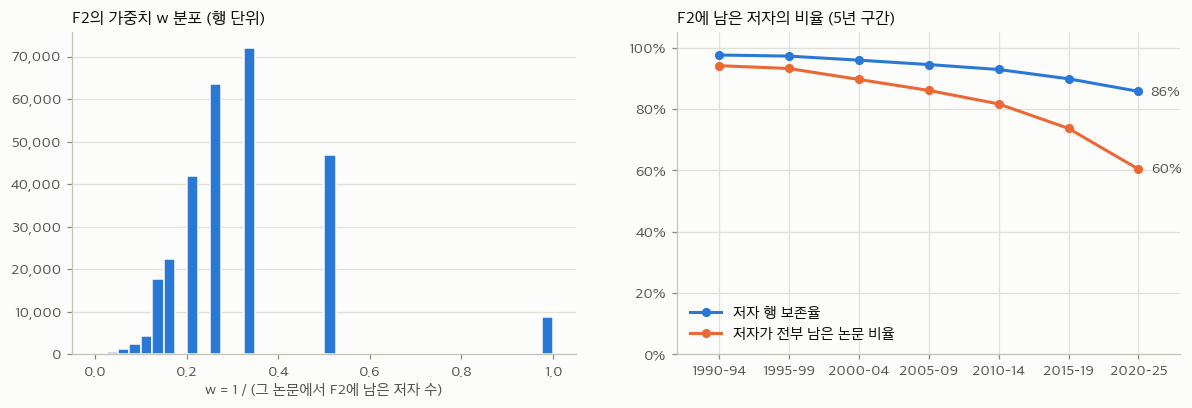

**요약**
- F2는 논문 87,525편, 저자 이름 101,842개다. `w`는 논문마다 합이 1이 되도록 **F2에 남은 저자 수로** 나눈 값이다.
- 그래서 `w`는 `1/n_authors`와 다를 수 있다. 저자가 전부 남은 논문은 73.8%뿐이고, 나머지 26.2%는 위험군 제외 등으로 저자 일부가 빠져 **남은 저자의 `w`가 실제 몫보다 크다.** 행 기준으로는 25.2%가 `1/n_authors`보다 큰 `w`를 가진다.
- 빠지는 정도가 시기마다 다르다. 저자 행 보존율이 1990–94년 98%에서 2020–25년 86%로 낮아진다. 빠진 저자가 누구인지는 F7과 겹치는 2020–25년 논문 30,422편에서 확인할 수 있다. 빠진 저자 행 17,289개 중 **99.2%가 위험군 이름**이고, 나머지는 이름 결측 46개와 한 논문 안의 같은 이름 중복 85개다. 2019년 이전은 F7이 없어 같은 확인을 할 수 없다.
- 주제가 있는데도 저자가 전원 빠져 F2에 없는 논문이 639편 있다(연도 중앙값 2018년). F3·F6의 기간별 질량은 이 논문들을 포함하지 않는다.

In [14]:
pp = F2.groupby("pid").agg(rows=("name_norm", "size"), n=("n_authors", "first"), year=("year", "first"), wsum=("w", "sum"))
pp["p5"] = np.minimum(pp.year // 5 * 5, 2020)
covp = pp[pp.year >= 1990].groupby("p5").apply(lambda d: pd.Series({"저자 행 보존율": d.rows.sum() / d.n.sum(), "저자가 전부 남은 논문 비율": (d.rows == d.n).mean()}))
xl2 = [f"{p}–{str(p+4)[2:]}" if p < 2020 else "2020–25" for p in covp.index]
wv = F2.w.round(4).value_counts().sort_index(ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].hist(F2.w, bins=np.linspace(0, 1, 41), color=C["blue"], **BAR); ax[0].set_title("F2의 가중치 w 분포 (행 단위)"); ax[0].yaxis.set_major_formatter(comma)
ax[0].set_xlabel("w = 1 / (그 논문에서 F2에 남은 저자 수)"); ax[0].grid(axis="x", visible=False)
for (lab, col), c in zip(covp.items(), [C["blue"], C["orange"]]):
    ax[1].plot(xl2, col, color=c, marker="o", markersize=5, label=lab)
    ax[1].annotate(f"{col.iloc[-1]:.0%}", (len(xl2) - 1, col.iloc[-1]), xytext=(8, 0), textcoords="offset points", va="center", color=C["ink2"])
ax[1].set_ylim(0, 1.05); ax[1].yaxis.set_major_formatter(pct0); ax[1].set_title("F2에 남은 저자의 비율 (5년 구간)"); ax[1].legend(loc="lower left"); ax[1].margins(x=.1)
save(fig, "F2_01_가중치_저자보존율")

n_topic, n_f2p = int(F1.has_topic.sum()), F2.pid.nunique(); lost = F1[F1.has_topic & ~F1.pid.isin(F2.pid)]
w_eq = np.isclose(F2.w, 1 / F2.n_authors).mean(); full = (pp.rows == pp.n).mean()
check("4", "F2의 w는 논문마다 합이 정확히 1이다(전체 합 = F2의 논문 수 87,525)", np.allclose(pp.wsum, 1) and n_f2p == 87525, f"{F2.w.sum():.1f}")
check("4", "w는 1/(그 논문의 F2 행 수)와 같다", np.allclose(F2.w, 1 / F2.pid.map(pp.rows)))
check("4", "F2 행 수가 n_authors보다 많은 논문은 없고, author_pos는 1 이상 n_authors 이하다", (pp.rows <= pp.n).all() and F2.author_pos.between(1, F2.n_authors).all())
check("4", "주제가 있는 논문 88,164편 중 639편은 F2에 저자가 한 명도 없다", n_topic - n_f2p == 639 and len(lost) == 639, n_topic - n_f2p)
check("4", "저자가 전부 F2에 남은 논문은 73.8%이고, w가 1/n_authors와 같은 행은 74.8%다", (round(full, 3), round(w_eq, 3)) == (0.738, 0.748), (round(full, 4), round(w_eq, 4)))
both = pp.index[pp.index.isin(F7.pid)]; f7b = F7[F7.pid.isin(both)]; r_, n_ = f7b.name_norm.isin(RISK.name_norm), f7b.name_norm.isna()
kept = f7b[~r_ & ~n_].drop_duplicates(["pid", "name_norm"]); lostrows = len(f7b) - len(kept)
same_rows = (kept.groupby("pid").size().reindex(both, fill_value=0) == pp.rows[both]).all()
check("4", "F7과 겹치는 논문에서는 F7 저자 중 위험군·이름 결측·같은 이름 중복을 빼면 F2의 행 수와 정확히 같다", same_rows, f"{len(both):,}편")
check("4", "그 논문들에서 F2에 빠진 저자 행의 99% 이상이 위험군 이름이다", r_.sum() / lostrows > .99, f"{r_.sum():,}/{lostrows:,}")
check("4", "F2에서 한 이름이 한 해에 가진 논문은 최대 11편이다(위험군 기준 12편 미만)", F2.groupby(["name_norm", "year"]).size().max() == 11, int(F2.groupby(["name_norm", "year"]).size().max()))
md(f"""**요약**
- F2는 논문 {n_f2p:,}편, 저자 이름 {F2.name_norm.nunique():,}개다. `w`는 논문마다 합이 1이 되도록 **F2에 남은 저자 수로** 나눈 값이다.
- 그래서 `w`는 `1/n_authors`와 다를 수 있다. 저자가 전부 남은 논문은 {full:.1%}뿐이고, 나머지 {1-full:.1%}는 위험군 제외 등으로 저자 일부가 빠져 **남은 저자의 `w`가 실제 몫보다 크다.** 행 기준으로는 {1-w_eq:.1%}가 `1/n_authors`보다 큰 `w`를 가진다.
- 빠지는 정도가 시기마다 다르다. 저자 행 보존율이 1990–94년 {covp['저자 행 보존율'].iloc[0]:.0%}에서 2020–25년 {covp['저자 행 보존율'].iloc[-1]:.0%}로 낮아진다. 빠진 저자가 누구인지는 F7과 겹치는 2020–25년 논문 {len(both):,}편에서 확인할 수 있다. 빠진 저자 행 {lostrows:,}개 중 **{r_.sum()/lostrows:.1%}가 위험군 이름**이고, 나머지는 이름 결측 {n_.sum()}개와 한 논문 안의 같은 이름 중복 {lostrows - r_.sum() - n_.sum()}개다. 2019년 이전은 F7이 없어 같은 확인을 할 수 없다.
- 주제가 있는데도 저자가 전원 빠져 F2에 없는 논문이 {len(lost):,}편 있다(연도 중앙값 {lost.year.median():.0f}년). F3·F6의 기간별 질량은 이 논문들을 포함하지 않는다.""")

In [15]:
xt = pd.crosstab(RISK.ambiguous.map({True: "ambiguous=True", False: "ambiguous=False"}), RISK.heavy.map({True: "heavy=True", False: "heavy=False"}), margins=True, margins_name="합계")
display(xt)
check("4", "위험군 1,431개 = ambiguous만 1,223 + heavy만 118 + 둘 다 90", (len(RISK), xt.loc["ambiguous=True", "heavy=False"], xt.loc["ambiguous=False", "heavy=True"], xt.loc["ambiguous=True", "heavy=True"]) == (1431, 1223, 118, 90))
md(f"""**요약**
- 위험군 이름 {len(RISK):,}개 중 {RISK.ambiguous.sum():,}개({RISK.ambiguous.mean():.0%})가 `ambiguous`(이름 매칭이 모호), {RISK.heavy.sum()}개가 `heavy`(한 해 12편 이상)이고 {int((RISK.ambiguous & RISK.heavy).sum())}개는 둘 다다. 두 플래그가 모두 False인 행은 없다.
- 위험군은 이름 수로는 적지만(전체 저자 이름 대비 약 {len(RISK)/(len(F4)+len(RISK)):.1%}) F2에서 빠진 저자 행은 전체의 {1 - pp.rows.sum()/pp.n.sum():.1%}에 이른다(위 그림). 8절에서 OpenAlex ID로 이 지정이 타당한지 본다.""")

heavy,heavy=False,heavy=True,합계
ambiguous,,,
ambiguous=False,0,118,118
ambiguous=True,1223,90,1313
합계,1223,208,1431


**요약**
- 위험군 이름 1,431개 중 1,313개(92%)가 `ambiguous`(이름 매칭이 모호), 208개가 `heavy`(한 해 12편 이상)이고 90개는 둘 다다. 두 플래그가 모두 False인 행은 없다.
- 위험군은 이름 수로는 적지만(전체 저자 이름 대비 약 1.0%) F2에서 빠진 저자 행은 전체의 10.6%에 이른다(위 그림). 8절에서 OpenAlex ID로 이 지정이 타당한지 본다.

## 5. F3 — 저자×기간×저널×주제 (291,488행)

### 5.1 기간별 규모와 F2로부터의 재현

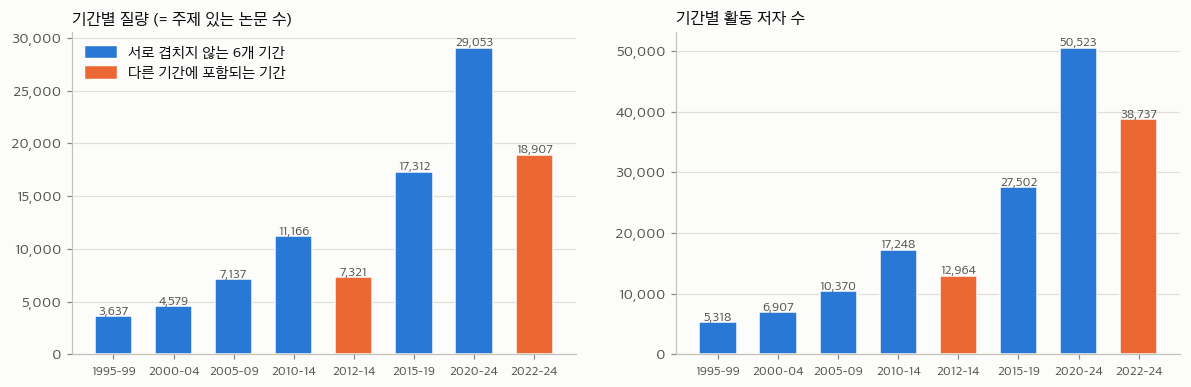

,기간,행수,질량,F2 논문 수,저자수
period,,,,,
P95_99,1995–99,"7,759","3,637.0","3,637","5,318"
P00_04,2000–04,"10,433","4,579.0","4,579","6,907"
P05_09,2005–09,"16,060","7,137.0","7,137","10,370"
P10_14,2010–14,"29,653","11,166.0","11,166","17,248"
P12_14,2012–14,"20,376","7,321.0","7,321","12,964"
P15_19,2015–19,"49,565","17,312.0","17,312","27,502"
P20_24,2020–24,"93,604","29,053.0","29,053","50,523"
P22_24,2022–24,"64,038","18,907.0","18,907","38,737"


**요약**
- F3는 F2를 기간별로 합친 것과 정확히 같다. 기간별 질량 합은 그 기간의 논문 수와 같다(논문 1편 = 질량 1).
- 질량은 1995–99년 3,637에서 2020–24년 29,053로 **8.0배**가 됐고, 활동 저자 수는 5,318명에서 50,523명으로 **9.5배**가 됐다. 기간 사이의 변화를 볼 때 이 팽창을 먼저 감안해야 한다.
- 주황색 두 기간은 다른 기간의 부분집합이다. 8개 기간을 합산하면 논문이 중복 집계된다.
- F3가 덮는 범위는 1995–2024년이다. **1994년 이전과 2025년의 저자-논문 45,081행(16.0%)은 F3에 없다.** 그 구간은 F2로 직접 집계해야 한다.

In [16]:
rb = pd.concat([F2[F2.year.between(a, b)].groupby(["name_norm", "venue_short", "topic150"]).w.sum().reset_index().assign(period=p) for p, (a, b) in PER.items()])
mm = F3.merge(rb, on=["name_norm", "period", "venue_short", "topic150"], how="outer", suffixes=("", "_re"), indicator=True)
f3ok = (mm._merge == "both").all() and np.allclose(mm.w, mm.w_re)
ps = F3.groupby("period").agg(행수=("w", "size"), 질량=("w", "sum"), 저자수=("name_norm", "nunique")).reindex(PER)
ps["F2 논문 수"] = [F2[F2.year.between(a, b)].pid.nunique() for a, b in PER.values()]
ps["기간"] = [PLAB[p] for p in ps.index]
colp = [C["orange"] if p in ("P12_14", "P22_24") else C["blue"] for p in ps.index]
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for a in ax: a.tick_params(axis="x", labelsize=8.5)
for a, c, t in zip(ax, ["질량", "저자수"], ["기간별 질량 (= 주제 있는 논문 수)", "기간별 활동 저자 수"]):
    a.bar(ps.기간, ps[c], color=colp, width=0.62, **BAR); a.set_title(t); a.yaxis.set_major_formatter(comma); a.grid(axis="x", visible=False)
    for i, v in enumerate(ps[c]): a.text(i, v, f"{v:,.0f}", ha="center", va="bottom", fontsize=8.5, color=C["ink2"])
ax[0].legend(handles=[mpl.patches.Patch(color=C["blue"], label="서로 겹치지 않는 6개 기간"), mpl.patches.Patch(color=C["orange"], label="다른 기간에 포함되는 기간")], loc="upper left")
save(fig, "F3_01_기간별_질량_저자수")
display(ps[["기간", "행수", "질량", "F2 논문 수", "저자수"]].style.format({"행수": "{:,}", "질량": "{:,.1f}", "F2 논문 수": "{:,}", "저자수": "{:,}"}))
out_rng = F2[~F2.year.between(1995, 2024)]
check("5.1", "F3는 F2를 8개 기간으로 집계한 결과와 행·값이 모두 같다", f3ok)
check("5.1", "기간별 질량 합은 그 기간의 F2 논문 수와 같다", np.allclose(ps.질량, ps["F2 논문 수"]))
check("5.1", "P12_14는 P10_14에, P22_24는 P20_24에 포함된다(저자별 질량이 항상 작거나 같다)", (F4.m_P12_14 <= F4.m_P10_14 + 1e-9).all() and (F4.m_P22_24 <= F4.m_P20_24 + 1e-9).all())
check("5.1", "F3의 8개 기간은 1995–2024년만 덮는다. 그 밖(1994년 이전, 2025년)의 F2 행은 F3에 없다", len(out_rng) > 0 and F2[F2.year.between(1995, 2024)].name_norm.nunique() == F3.name_norm.nunique(), f"{len(out_rng):,}행")
md(f"""**요약**
- F3는 F2를 기간별로 합친 것과 정확히 같다. 기간별 질량 합은 그 기간의 논문 수와 같다(논문 1편 = 질량 1).
- 질량은 1995–99년 {ps.질량['P95_99']:,.0f}에서 2020–24년 {ps.질량['P20_24']:,.0f}로 **{ps.질량['P20_24']/ps.질량['P95_99']:.1f}배**가 됐고, 활동 저자 수는 {ps.저자수['P95_99']:,}명에서 {ps.저자수['P20_24']:,}명으로 **{ps.저자수['P20_24']/ps.저자수['P95_99']:.1f}배**가 됐다. 기간 사이의 변화를 볼 때 이 팽창을 먼저 감안해야 한다.
- 주황색 두 기간은 다른 기간의 부분집합이다. 8개 기간을 합산하면 논문이 중복 집계된다.
- F3가 덮는 범위는 1995–2024년이다. **1994년 이전과 2025년의 저자-논문 {len(out_rng):,}행({len(out_rng)/len(F2):.1%})은 F3에 없다.** 그 구간은 F2로 직접 집계해야 한다.""")

### 5.2 저자 한 명이 한 기간에 갖는 질량과 주제 수

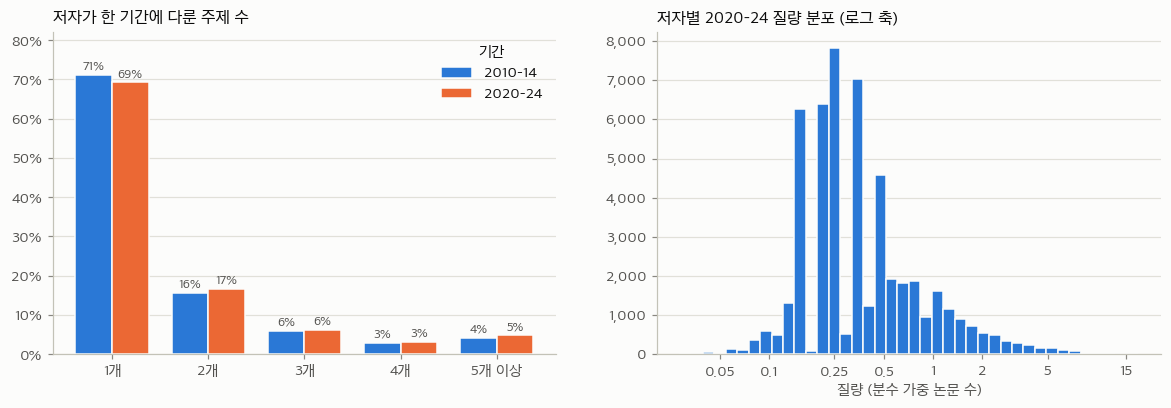

,name_norm,period,venue_short,topic150,w,top_words
147162,claudio casetti,P20_24,VT Mag,38,15.0,"radio, mimo, spectrum, reconfigurable, interference, communications"
45919,javier gozalvez,P10_14,VT Mag,38,12.0,"radio, mimo, spectrum, reconfigurable, interference, communications"
112805,matthias patzold,P15_19,VT Mag,38,11.0,"radio, mimo, spectrum, reconfigurable, interference, communications"


**요약**
- **저자 대부분은 한 기간에 주제가 하나뿐이다.** 2010–14년 71%, 2020–24년 69%가 주제 1개다. 주제 2개 이상인 저자는 2010–14년 4,965명, 2020–24년 15,540명이다.
- 저자별 질량도 작다. 2020–24년 중앙값 0.33(3인 논문 1편 몫), 상위 10% 기준 1.17, 상위 1% 기준 4.56다. 한 저자의 "주제 분포"는 대부분 논문 한두 편으로 정해지는 거친 값이다.
- 따라서 저자 개인 단위의 주제 분포 비교는 잡음이 크고, **주제 동시출현(한 저자가 한 기간에 여러 주제를 다룸)을 쓰는 분석은 기간별로 25%~31%의 저자에게서만 정보가 나온다.**
- F3의 최댓값(15, 12, 11)은 모두 VT Mag의 38번 주제에서 나온다. 가장 큰 값은 한 저자가 단독으로 실은 15편이고 제목이 모두 `[Mobile Radio]`로 끝나는 잡지 고정 칼럼이다. 연구 논문이 아닌 항목이 주제 분석에 들어가 있다는 뜻이다.

In [17]:
ap = F3.groupby(["name_norm", "period"]).agg(m=("w", "sum"), nt=("topic150", "nunique"), nv=("venue_short", "nunique")).reset_index()
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
bins = ["1개", "2개", "3개", "4개", "5개 이상"]; x = np.arange(5); wd = .38
for i, (p, c) in enumerate(zip(["P10_14", "P20_24"], [C["blue"], C["orange"]])):
    g = ap[ap.period == p].nt.clip(upper=5).value_counts(normalize=True).reindex(range(1, 6))
    ax[0].bar(x + (i - .5) * wd, g.values, width=wd, color=c, label=PLAB[p], **BAR)
    for xi, v in zip(x, g.values): ax[0].text(xi + (i - .5) * wd, v + .012, f"{v:.0%}", ha="center", fontsize=8.5, color=C["ink2"])
ax[0].set_xticks(x); ax[0].set_xticklabels(bins); ax[0].set_ylim(0, .82); ax[0].yaxis.set_major_formatter(pct0); ax[0].legend(title="기간")
ax[0].set_title("저자가 한 기간에 다룬 주제 수"); ax[0].grid(axis="x", visible=False)
g = ap[ap.period == "P20_24"].m
ax[1].hist(np.log10(g), bins=40, color=C["blue"], **BAR); ax[1].set_xticks(np.log10([.05, .1, .25, .5, 1, 2, 5, 15])); ax[1].set_xticklabels(["0.05", "0.1", "0.25", "0.5", "1", "2", "5", "15"])
ax[1].set_title("저자별 2020–24 질량 분포 (로그 축)"); ax[1].set_xlabel("질량 (분수 가중 논문 수)"); ax[1].yaxis.set_major_formatter(comma); ax[1].grid(axis="x", visible=False)
save(fig, "F3_02_저자별_주제수_질량")
one = ap.groupby("period").nt.apply(lambda s: (s == 1).mean()).reindex(MAINP); two = ap.groupby("period").nt.apply(lambda s: (s >= 2).sum()).reindex(MAINP)
q20 = g.quantile([.5, .9, .99]); topw = F3.nlargest(3, "w")
check("5.2", "어느 기간에서든 활동 저자의 69~76%는 주제가 1개뿐이다", one.between(.69, .76).all(), one.round(3).to_dict())
check("5.2", "2020–24 저자별 질량의 중앙값은 1/3, 즉 3인 논문 1편 몫이다", np.isclose(q20[.5], 1 / 3), q20.round(3).to_dict())
col_ = F2[(F2.name_norm == topw.name_norm.iloc[0]) & (F2.venue_short == "VT Mag") & (F2.topic150 == 38) & F2.year.between(2020, 2024)].merge(F1[["pid", "title"]], on="pid")
col_tag = col_.title.str.contains("[Mobile Radio]", regex=False).mean()
check("5.2", "가장 큰 w(15)는 한 저자가 VT Mag에 단독으로 실은 15편이고, 제목이 모두 '[Mobile Radio]' 고정 칼럼이다", len(col_) == 15 and (col_.w == 1).all() and col_tag == 1, (len(col_), col_tag))
check("5.2", "F3에서 가장 큰 w 세 행은 모두 VT Mag의 38번 주제다", (topw.venue_short == "VT Mag").all() and (topw.topic150 == 38).all(), topw.w.tolist())
display(topw.assign(top_words=topw.topic150.map(F6.top_words)))
md(f"""**요약**
- **저자 대부분은 한 기간에 주제가 하나뿐이다.** 2010–14년 {one['P10_14']:.0%}, 2020–24년 {one['P20_24']:.0%}가 주제 1개다. 주제 2개 이상인 저자는 2010–14년 {two['P10_14']:,}명, 2020–24년 {two['P20_24']:,}명이다.
- 저자별 질량도 작다. 2020–24년 중앙값 {q20[.5]:.2f}({round(1/q20[.5])}인 논문 1편 몫), 상위 10% 기준 {q20[.9]:.2f}, 상위 1% 기준 {q20[.99]:.2f}다. 한 저자의 "주제 분포"는 대부분 논문 한두 편으로 정해지는 거친 값이다.
- 따라서 저자 개인 단위의 주제 분포 비교는 잡음이 크고, **주제 동시출현(한 저자가 한 기간에 여러 주제를 다룸)을 쓰는 분석은 기간별로 {1-one.max():.0%}~{1-one.min():.0%}의 저자에게서만 정보가 나온다.**
- F3의 최댓값({topw.w.iloc[0]:.0f}, {topw.w.iloc[1]:.0f}, {topw.w.iloc[2]:.0f})은 모두 VT Mag의 38번 주제에서 나온다. 가장 큰 값은 한 저자가 단독으로 실은 {len(col_)}편이고 제목이 모두 `[Mobile Radio]`로 끝나는 잡지 고정 칼럼이다. 연구 논문이 아닌 항목이 주제 분석에 들어가 있다는 뜻이다.""")

## 6. F4 — 저자표 (140,553명)

### 6.1 생산성, 경력, 코호트

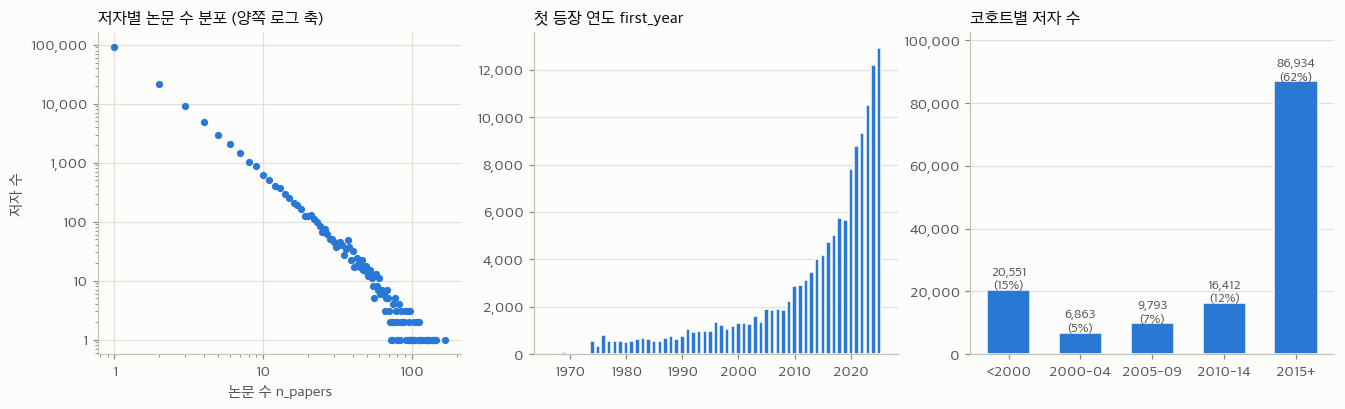

**요약**
- 저자별 논문 수는 전형적인 긴 꼬리 분포다. **65.4%가 1편**, 중앙값 1편, 상위 10% 기준 4편, 상위 1% 기준 22편, 최대 167편이다. 상위 1% 저자가 전체 저자-논문 건수의 16.0%를 차지한다.
- 68.9%는 첫 연도와 마지막 연도가 같고, 79.8%는 저널 1곳에만 등장한다. 대다수는 이 코퍼스에 한 번 스쳐 가는 저자다.
- 코호트는 `2015+`가 86,934명(62%)으로 가장 크다. 2020년 이후에 처음 등장한 저자만 61,592명(44%)이다.
- `first_year`와 `n_papers`는 주제 없는 논문까지 포함해 계산된 값이다. F2에도 있는 저자 중 6.5%는 `n_papers`가 F2에서 센 논문 수보다 크다. **F4의 경력 변수와 F2·F3의 질량은 기준이 다르다.**

In [18]:
npd = F4.n_papers.value_counts().sort_index()
fy = F4.first_year.value_counts().sort_index()
CO = ["<2000", "2000-04", "2005-09", "2010-14", "2015+"]; cs = F4.cohort.value_counts().reindex(CO)
fig, ax = plt.subplots(1, 3, figsize=(14.5, 3.8))
ax[0].scatter(npd.index, npd.values, s=14, color=C["blue"]); ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set_title("저자별 논문 수 분포 (양쪽 로그 축)"); ax[0].set_xlabel("논문 수 n_papers"); ax[0].set_ylabel("저자 수"); ax[0].xaxis.set_major_formatter(comma); ax[0].yaxis.set_major_formatter(comma)
ax[1].bar(fy.index, fy.values, color=C["blue"], width=0.8, **BAR); ax[1].set_title("첫 등장 연도 first_year"); ax[1].yaxis.set_major_formatter(comma); ax[1].grid(axis="x", visible=False)
ax[2].bar(cs.index, cs.values, color=C["blue"], width=0.6, **BAR); ax[2].set_title("코호트별 저자 수"); ax[2].yaxis.set_major_formatter(comma); ax[2].grid(axis="x", visible=False)
for i, v in enumerate(cs.values): ax[2].text(i, v, f"{v:,}\n({v/len(F4):.0%})", ha="center", va="bottom", fontsize=8.5, color=C["ink2"])
ax[2].set_ylim(0, cs.max() * 1.18)
save(fig, "F4_01_생산성_첫등장_코호트")

co = np.select([F4.first_year < 2000, F4.first_year < 2005, F4.first_year < 2010, F4.first_year < 2015], CO[:4], "2015+")
one_p, one_y, one_v = (F4.n_papers == 1).mean(), (F4.first_year == F4.last_year).mean(), (F4.n_venues == 1).mean()
top1p = F4.n_papers.nlargest(len(F4) // 100).sum() / F4.n_papers.sum()
j = F4.set_index("name_norm").join(F2.groupby("name_norm").agg(fy2=("year", "min"), n2=("pid", "nunique")), how="inner")
check("6.1", "cohort는 first_year로 재계산한 값과 같고, last_year ≥ first_year다", (co == F4.cohort).all() and (F4.last_year >= F4.first_year).all())
check("6.1", "저자의 65.4%는 논문이 1편뿐이다", round(one_p, 3) == .654, f"{one_p:.4f}")
check("6.1", "F4의 n_papers·first_year는 주제 없는 논문까지 포함한다: F2에서 센 논문 수보다 항상 크거나 같고, 첫 연도는 항상 같거나 이르다", (j.n_papers >= j.n2).all() and (j.first_year <= j.fy2).all(), f"논문 수가 더 큰 저자 {(j.n_papers > j.n2).mean():.1%}")
md(f"""**요약**
- 저자별 논문 수는 전형적인 긴 꼬리 분포다. **{one_p:.1%}가 1편**, 중앙값 {F4.n_papers.median():.0f}편, 상위 10% 기준 {F4.n_papers.quantile(.9):.0f}편, 상위 1% 기준 {F4.n_papers.quantile(.99):.0f}편, 최대 {F4.n_papers.max()}편이다. 상위 1% 저자가 전체 저자-논문 건수의 {top1p:.1%}를 차지한다.
- {one_y:.1%}는 첫 연도와 마지막 연도가 같고, {one_v:.1%}는 저널 1곳에만 등장한다. 대다수는 이 코퍼스에 한 번 스쳐 가는 저자다.
- 코호트는 `2015+`가 {cs['2015+']:,}명({cs['2015+']/len(F4):.0%})으로 가장 크다. 2020년 이후에 처음 등장한 저자만 {(F4.first_year >= 2020).sum():,}명({(F4.first_year >= 2020).mean():.0%})이다.
- `first_year`와 `n_papers`는 주제 없는 논문까지 포함해 계산된 값이다. F2에도 있는 저자 중 {(j.n_papers > j.n2).mean():.1%}는 `n_papers`가 F2에서 센 논문 수보다 크다. **F4의 경력 변수와 F2·F3의 질량은 기준이 다르다.**""")

### 6.2 기간별 활동과 지속·신규 저자

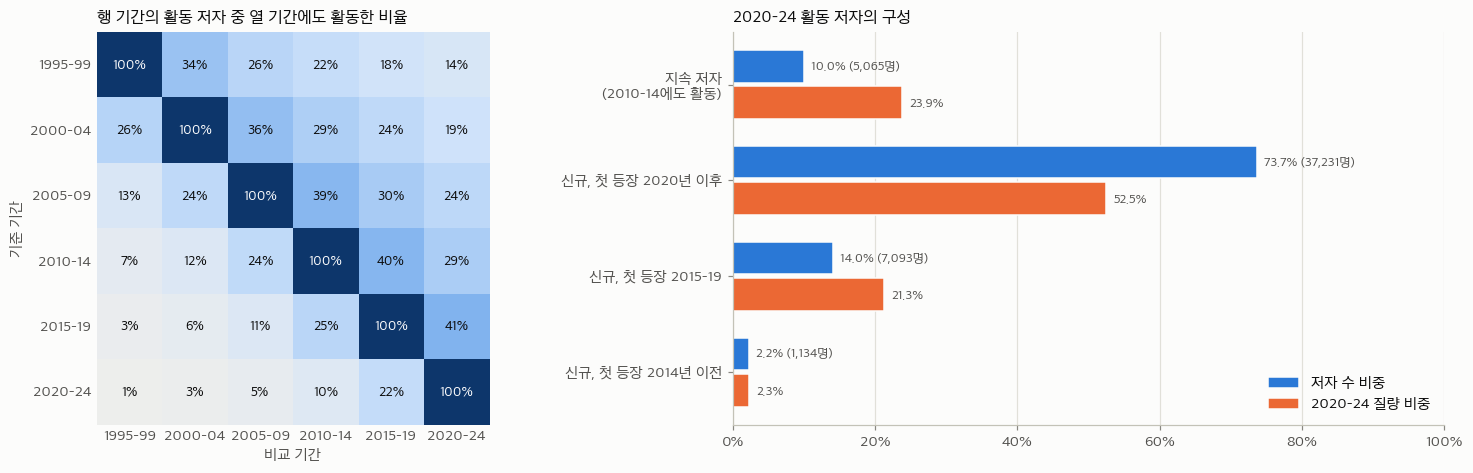

**요약**
- **지속 저자는 소수다.** 2010–14년 활동 저자 17,248명 중 2020–24년에도 활동한 저자는 5,065명(29.4%)이다. 2020–24년 쪽에서 보면 저자 수의 10.0%, 질량의 23.9%다.
- 바로 다음 기간으로 이어지는 저자도 34%~41%에 그친다(왼쪽 그림의 대각선 오른쪽 칸). 기간을 멀리 잡을수록 지속 저자 표본은 더 작아진다.
- 신규 저자 45,458명 중 81.9%는 실제로 2020년 이후에 처음 등장했고, 15.6%는 2015–19년에 처음 등장했다. 2014년 이전부터 있던 저자는 2.5%뿐이라, `entrant_main`은 이름 그대로 "새로 들어온 저자"로 읽어도 큰 무리가 없다.
- F4의 52,581명(37.4%)은 어느 기간에도 질량이 없다. 이 중 38,711명은 주제 있는 논문이 하나도 없어 F2에 아예 없고, 13,870명은 F2에 있지만 논문이 1994년 이전이나 2025년에만 있다. **F4에서 주제 분석에 쓸 수 있는 저자는 87,972명**이다.

In [19]:
act = pd.DataFrame({p: F4[f"m_{p}"] > 0 for p in MAINP})
OVL = pd.DataFrame([[(act[a] & act[b]).sum() / act[a].sum() for b in MAINP] for a in MAINP], index=[PLAB[p] for p in MAINP], columns=[PLAB[p] for p in MAINP])
fig, ax = plt.subplots(1, 2, figsize=(14, 4.4), gridspec_kw={"width_ratios": [1, 1.1]})
im = ax[0].imshow(OVL.values, cmap=SEQ, vmin=0, vmax=1); ax[0].grid(False); ax[0].tick_params(length=0)
for s in ax[0].spines.values(): s.set_visible(False)
ax[0].set_xticks(range(6)); ax[0].set_xticklabels(OVL.columns); ax[0].set_yticks(range(6)); ax[0].set_yticklabels(OVL.index)
for i in range(6):
    for k in range(6): ax[0].text(k, i, f"{OVL.values[i, k]:.0%}", ha="center", va="center", fontsize=9, color="white" if OVL.values[i, k] > .55 else C["ink"])
ax[0].set_title("행 기간의 활동 저자 중 열 기간에도 활동한 비율"); ax[0].set_ylabel("기준 기간"); ax[0].set_xlabel("비교 기간")

e = F4[F4.entrant_main]; c_ = F4[F4.continuing_main]; tot = F4.m_P20_24.sum()
grp = pd.DataFrame({
    "지속 저자\n(2010–14에도 활동)": [len(c_), c_.m_P20_24.sum() / tot],
    "신규, 첫 등장 2020년 이후": [(e.first_year >= 2020).sum(), e.m_P20_24[e.first_year >= 2020].sum() / tot],
    "신규, 첫 등장 2015–19": [e.first_year.between(2015, 2019).sum(), e.m_P20_24[e.first_year.between(2015, 2019)].sum() / tot],
    "신규, 첫 등장 2014년 이전": [(e.first_year < 2015).sum(), e.m_P20_24[e.first_year < 2015].sum() / tot]}, index=["저자 수", "질량 비중"]).T
y = np.arange(len(grp))[::-1]
ax[1].barh(y + .19, grp["저자 수"] / grp["저자 수"].sum(), height=.34, color=C["blue"], label="저자 수 비중", **BAR)
ax[1].barh(y - .19, grp["질량 비중"], height=.34, color=C["orange"], label="2020–24 질량 비중", **BAR)
for yi, (n, m) in zip(y, grp.values):
    ax[1].text(n / grp["저자 수"].sum() + .01, yi + .19, f"{n/grp['저자 수'].sum():.1%} ({n:,.0f}명)", va="center", fontsize=8.5, color=C["ink2"])
    ax[1].text(m + .01, yi - .19, f"{m:.1%}", va="center", fontsize=8.5, color=C["ink2"])
ax[1].set_yticks(y); ax[1].set_yticklabels(grp.index); ax[1].set_xlim(0, 1); ax[1].xaxis.set_major_formatter(pct0); ax[1].grid(axis="y", visible=False)
ax[1].set_title("2020–24 활동 저자의 구성"); ax[1].legend(loc="lower right")
fig.tight_layout(); save(fig, "F4_02_기간중첩_지속신규")

mass = F3.groupby(["name_norm", "period"]).w.sum().unstack(fill_value=0)
m_ok = all(np.allclose(F4[f"m_{p}"].values, mass[p].reindex(F4.name_norm).fillna(0).values) for p in PER)
zero = F4[F4.filter(like="m_P").sum(axis=1) == 0]; z_in = zero.name_norm.isin(F2.name_norm)
check("6.2", "F4의 m_ 8개 열은 F3의 저자·기간별 질량 합과 같다", m_ok)
check("6.2", "continuing_main, entrant_main은 m_P10_14, m_P20_24로 재계산한 값과 같다. 지속 5,065명, 신규 45,458명", ((F4.m_P10_14 > 0) & (F4.m_P20_24 > 0) == F4.continuing_main).all() and ((F4.m_P10_14 == 0) & (F4.m_P20_24 > 0) == F4.entrant_main).all() and (len(c_), len(e)) == (5065, 45458), (len(c_), len(e)))
check("6.2", "2020–24 질량 중 지속 저자 몫은 23.9%다", round(grp['질량 비중'].iloc[0], 3) == .239, f"{grp['질량 비중'].iloc[0]:.4f}")
check("6.2", "2010–14 활동 저자 중 2020–24에도 활동한 비율은 29.4%다", round(OVL.loc['2010–14', '2020–24'], 3) == .294, f"{OVL.loc['2010–14','2020–24']:.4f}")
check("6.2", "신규 저자의 97.5%는 첫 등장이 2015년 이후다", round((e.first_year >= 2015).mean(), 3) == .975, f"{(e.first_year >= 2015).mean():.4f}")
check("6.2", "F4 저자 중 52,581명(37.4%)은 8개 기간 질량이 모두 0이다", len(zero) == 52581, len(zero))
zy = F2[F2.name_norm.isin(zero.name_norm)]
check("6.2", "그중 F2에 있는 13,870명은 주제 있는 논문이 모두 1994년 이전이거나 2025년이다", z_in.sum() == 13870 and not zy.year.between(1995, 2024).any(), int(z_in.sum()))
adj = [OVL.values[i, i + 1] for i in range(5)]
md(f"""**요약**
- **지속 저자는 소수다.** 2010–14년 활동 저자 {act.P10_14.sum():,}명 중 2020–24년에도 활동한 저자는 {len(c_):,}명({OVL.loc['2010–14','2020–24']:.1%})이다. 2020–24년 쪽에서 보면 저자 수의 {len(c_)/act.P20_24.sum():.1%}, 질량의 {grp['질량 비중'].iloc[0]:.1%}다.
- 바로 다음 기간으로 이어지는 저자도 {min(adj):.0%}~{max(adj):.0%}에 그친다(왼쪽 그림의 대각선 오른쪽 칸). 기간을 멀리 잡을수록 지속 저자 표본은 더 작아진다.
- 신규 저자 {len(e):,}명 중 {(e.first_year >= 2020).mean():.1%}는 실제로 2020년 이후에 처음 등장했고, {e.first_year.between(2015, 2019).mean():.1%}는 2015–19년에 처음 등장했다. 2014년 이전부터 있던 저자는 {(e.first_year < 2015).mean():.1%}뿐이라, `entrant_main`은 이름 그대로 "새로 들어온 저자"로 읽어도 큰 무리가 없다.
- F4의 {len(zero):,}명({len(zero)/len(F4):.1%})은 어느 기간에도 질량이 없다. 이 중 {(~z_in).sum():,}명은 주제 있는 논문이 하나도 없어 F2에 아예 없고, {z_in.sum():,}명은 F2에 있지만 논문이 1994년 이전이나 2025년에만 있다. **F4에서 주제 분석에 쓸 수 있는 저자는 {len(F4)-len(zero):,}명**이다.""")

## 7. F5 — 지속 저자표 (5,065명)

### 7.1 값의 재계산 검증

In [20]:
EMS, DCS, cont = set(F6.topic150[F6.emerging]), set(F6.topic150[F6.declining]), set(F5.name_norm)
def per_author(y0, y1, tag):
    g = F2[F2.name_norm.isin(cont) & F2.year.between(y0, y1)].copy()
    g["we"], g["wd"] = g.w * g.topic150.isin(EMS), g.w * g.topic150.isin(DCS)
    o = g.groupby("name_norm").agg(m=("w", "sum"), we=("we", "sum"), wd=("wd", "sum"), n=("pid", "nunique"))
    return pd.DataFrame({f"m{tag}": o.m, f"em{tag}": o.we / o.m, f"dc{tag}": o.wd / o.m, f"n{tag}": o.n})
X = per_author(2010, 2014, "0").join(per_author(2020, 2024, "1")).reindex(F5.name_norm)
b0 = F2[F2.year.between(2010, 2014)]
mv = b0.groupby(["name_norm", "venue_short"]).w.sum().reset_index(); mv["mx"] = mv.groupby("name_norm").w.transform("max")
best = mv[np.isclose(mv.w, mv.mx)].groupby("name_norm").venue_short.agg(set).reindex(F5.name_norm)
tie = (best.map(len) > 1).mean(); in_best = np.mean([v in s for v, s in zip(F5.main_venue0, best)])
f4i = F4.set_index("name_norm").reindex(F5.name_norm)
check("7.1", "F5의 m0, em0, dc0, m1, em1, dc1은 F2와 F6으로 재계산한 값과 같다", all(np.allclose(X[c].values, F5[c].values) for c in ["m0", "em0", "dc0", "m1", "em1", "dc1"]))
check("7.1", "d_em = em1 − em0, d_dc = dc1 − dc0", np.allclose(F5.d_em, F5.em1 - F5.em0) and np.allclose(F5.d_dc, F5.dc1 - F5.dc0))
check("7.1", "team0는 2010–14 논문의 평균 n_authors와 같고, first_year·cohort는 F4와 같다", np.allclose(F5.team0, F5.name_norm.map(b0.groupby("name_norm").n_authors.mean())) and (F5.first_year.values == f4i.first_year.values).all() and (F5.cohort.values == f4i.cohort.values).all())
check("7.1", "main_venue0는 2010–14 질량이 가장 큰 저널이다(동률이면 그중 하나)", in_best == 1, f"동률 저자 {tie:.1%}")
check("7.1", "평균 신생 비중은 0.058 → 0.133이다(구축 코드의 검산값)", (round(F5.em0.mean(), 3), round(F5.em1.mean(), 3)) == (.058, .133), (round(F5.em0.mean(), 4), round(F5.em1.mean(), 4)))
md(f"""**요약**
- F5의 질량·신생 비중·쇠퇴 비중·팀 규모·주 저널은 F2, F4, F6에서 다시 계산한 값과 모두 같다. 1절의 MD5 불일치는 내용 차이가 아니다.
- `main_venue0`는 2010–14년 질량이 가장 큰 저널인데, **{tie:.1%}의 저자는 1위 저널이 동률**이라 그중 하나가 임의로 들어가 있다.
- `coauthor_em0`와 `n_coauthors0`는 주제 없는 논문을 포함한 원자료로 계산된 값이라, 전달받은 9개 파일만으로는 재계산할 수 없다. 이 두 열은 분포만 확인한다.""")

**요약**
- F5의 질량·신생 비중·쇠퇴 비중·팀 규모·주 저널은 F2, F4, F6에서 다시 계산한 값과 모두 같다. 1절의 MD5 불일치는 내용 차이가 아니다.
- `main_venue0`는 2010–14년 질량이 가장 큰 저널인데, **5.4%의 저자는 1위 저널이 동률**이라 그중 하나가 임의로 들어가 있다.
- `coauthor_em0`와 `n_coauthors0`는 주제 없는 논문을 포함한 원자료로 계산된 값이라, 전달받은 9개 파일만으로는 재계산할 수 없다. 이 두 열은 분포만 확인한다.

### 7.2 질량과 신생·쇠퇴 비중의 분포

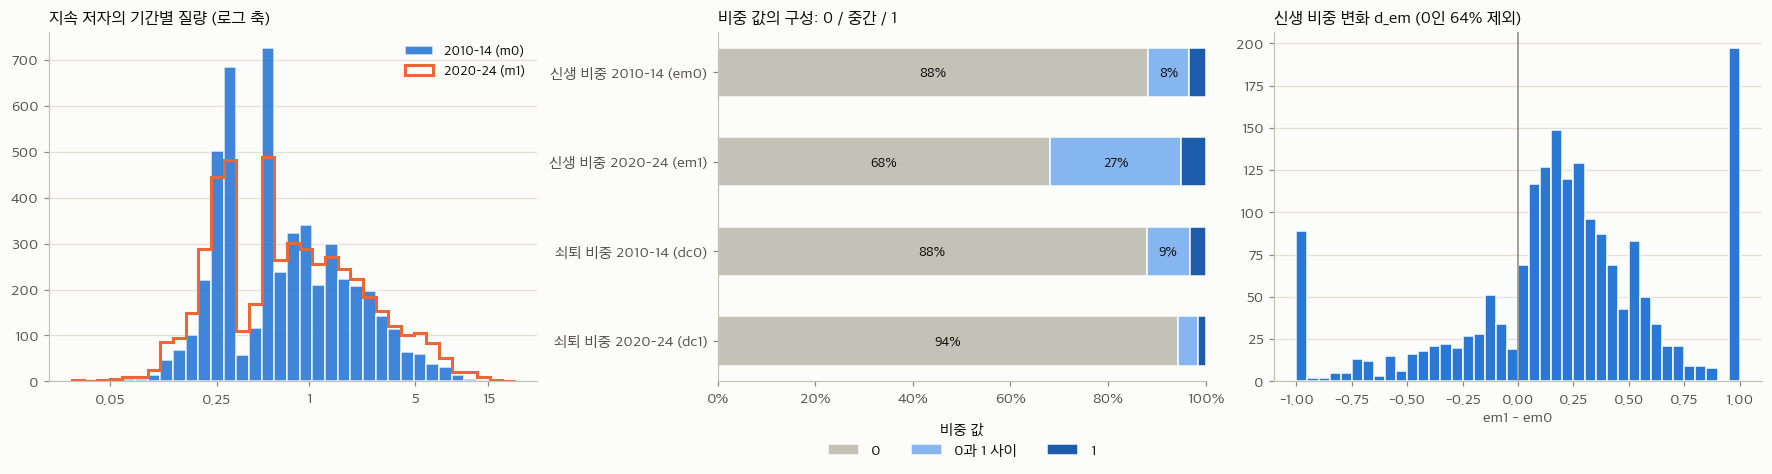

**요약**
- **지속 저자라고 해서 다작 저자는 아니다.** 2010–14년 질량의 중앙값이 0.58이고 63.5%가 질량 1 미만이다. 그 기간에 주제 있는 논문이 1편뿐인 저자가 41.6%(2020–24년은 33.7%)다.
- 그래서 비중 변수는 연속 변수처럼 보이지만 **실제로는 0 또는 1에 몰려 있다.** `em0`는 88.2%가 0, 3.3%가 1이고, `em1`은 68.1%가 0, 4.9%가 1이다.
- 변화량 `d_em`은 63.5%가 정확히 0이고, 늘어난 저자 28.4%, 줄어든 저자 8.1%다. 평균 +0.075는 **약 3분의 1의 저자가 움직여서** 나온 값이다. `d_dc`는 86.1%가 0이다.
- 이런 분포에서는 평균과 선형 회귀만으로 요약하기 어렵다. "움직였는가(0/1)"와 "얼마나 움직였는가"를 나눠 보거나, 저자 단위가 아닌 질량 가중 집계로 봐야 한다.

In [21]:
F5["n0"], F5["n1"] = X.n0.values, X.n1.values
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2), layout="constrained")
bn = np.linspace(-1.55, 1.35, 36)
ax[0].hist(np.log10(F5.m0), bins=bn, color=C["blue"], alpha=.9, label="2010–14 (m0)", **BAR)
ax[0].hist(np.log10(F5.m1), bins=bn, histtype="step", color=C["orange"], linewidth=2, label="2020–24 (m1)")
ax[0].set_xticks(np.log10([.05, .25, 1, 5, 15])); ax[0].set_xticklabels(["0.05", "0.25", "1", "5", "15"]); ax[0].set_title("지속 저자의 기간별 질량 (로그 축)"); ax[0].legend(loc="upper right", fontsize=9); ax[0].grid(axis="x", visible=False)
cats = ["0", "0과 1 사이", "1"]; cols3 = [C["gray"], "#86b6ef", "#1c5cab"]
Z = pd.DataFrame({c: [(F5[c] == 0).mean(), ((F5[c] > 0) & (F5[c] < 1)).mean(), (F5[c] == 1).mean()] for c in ["em0", "em1", "dc0", "dc1"]}, index=cats).T
left = np.zeros(4); yy = np.arange(4)[::-1]
for cat, cc in zip(cats, cols3):
    ax[1].barh(yy, Z[cat], left=left, color=cc, height=.55, label=cat, **BAR)
    for yi, l, v in zip(yy, left, Z[cat]):
        if v >= .06: ax[1].text(l + v / 2, yi, f"{v:.0%}", ha="center", va="center", fontsize=9, color="white" if cat == "1" else C["ink"])
    left += Z[cat].values
ax[1].set_yticks(yy); ax[1].set_yticklabels(["신생 비중 2010–14 (em0)", "신생 비중 2020–24 (em1)", "쇠퇴 비중 2010–14 (dc0)", "쇠퇴 비중 2020–24 (dc1)"])
ax[1].xaxis.set_major_formatter(pct0); ax[1].set_xlim(0, 1); ax[1].grid(False); ax[1].set_title("비중 값의 구성: 0 / 중간 / 1")
ax[1].legend(ncol=3, loc="upper center", bbox_to_anchor=(.5, -.08), title="비중 값")
nz = F5.d_em[F5.d_em != 0]
ax[2].hist(nz, bins=np.linspace(-1, 1, 41), color=C["blue"], **BAR); ax[2].axvline(0, color=C["muted"], linewidth=1)
ax[2].set_title(f"신생 비중 변화 d_em (0인 {(F5.d_em==0).mean():.0%} 제외)"); ax[2].set_xlabel("em1 - em0"); ax[2].grid(axis="x", visible=False)
save(fig, "F5_01_질량_비중분포")
check("7.2", "지속 저자의 2010–14 질량 중앙값은 0.58로 1편에 못 미친다. 63.5%가 질량 1 미만이다", (round(F5.m0.median(), 2), round((F5.m0 < 1).mean(), 3)) == (.58, .635), (round(F5.m0.median(), 3), round((F5.m0 < 1).mean(), 4)))
check("7.2", "em0는 88.2%가 0이고 91.5%가 0 또는 1이다", (round((F5.em0 == 0).mean(), 3), round(F5.em0.isin([0, 1]).mean(), 3)) == (.882, .915), (round((F5.em0 == 0).mean(), 4), round(F5.em0.isin([0, 1]).mean(), 4)))
check("7.2", "d_em은 63.5%가 정확히 0이다", round((F5.d_em == 0).mean(), 3) == .635, f"{(F5.d_em == 0).mean():.4f}")
check("7.2", "2010–14에 주제 있는 논문이 1편뿐인 지속 저자가 41.6%다", round((F5.n0 == 1).mean(), 3) == .416, f"{(F5.n0 == 1).mean():.4f}")
up, dn = (F5.d_em > 0).mean(), (F5.d_em < 0).mean()
md(f"""**요약**
- **지속 저자라고 해서 다작 저자는 아니다.** 2010–14년 질량의 중앙값이 {F5.m0.median():.2f}이고 {(F5.m0 < 1).mean():.1%}가 질량 1 미만이다. 그 기간에 주제 있는 논문이 1편뿐인 저자가 {(F5.n0 == 1).mean():.1%}(2020–24년은 {(F5.n1 == 1).mean():.1%})다.
- 그래서 비중 변수는 연속 변수처럼 보이지만 **실제로는 0 또는 1에 몰려 있다.** `em0`는 {(F5.em0 == 0).mean():.1%}가 0, {(F5.em0 == 1).mean():.1%}가 1이고, `em1`은 {(F5.em1 == 0).mean():.1%}가 0, {(F5.em1 == 1).mean():.1%}가 1이다.
- 변화량 `d_em`은 {(F5.d_em == 0).mean():.1%}가 정확히 0이고, 늘어난 저자 {up:.1%}, 줄어든 저자 {dn:.1%}다. 평균 +{F5.d_em.mean():.3f}는 **약 3분의 1의 저자가 움직여서** 나온 값이다. `d_dc`는 {(F5.d_dc == 0).mean():.1%}가 0이다.
- 이런 분포에서는 평균과 선형 회귀만으로 요약하기 어렵다. "움직였는가(0/1)"와 "얼마나 움직였는가"를 나눠 보거나, 저자 단위가 아닌 질량 가중 집계로 봐야 한다.""")

### 7.3 코호트별 평균과 그 밖의 변수

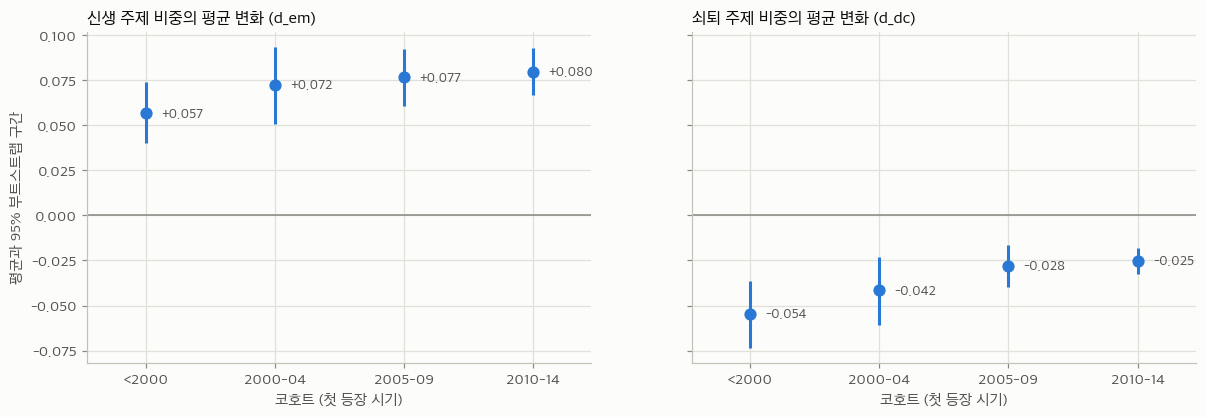

,n,m0,em0,em1,d_em,dc0,dc1,d_dc
cohort,,,,,,,,
<2000,689,2.110,0.041,0.098,0.057,0.109,0.054,-0.054
2000-04,504,1.765,0.034,0.107,0.072,0.086,0.044,-0.042
2005-09,1064,1.432,0.044,0.121,0.077,0.056,0.029,-0.028
2010-14,2808,0.693,0.071,0.151,0.080,0.046,0.021,-0.025


**요약**
- 지속 저자의 55.4%(2,808명)는 2010–14년에 처음 등장한 저자다. 이들은 2010–14년 평균 질량이 0.69로, `<2000` 코호트(2.11)의 3분의 1 수준이다. **"지속 저자"의 절반 이상은 당시 막 들어온 신진 저자**라는 뜻이다.
- 신생 비중의 평균 변화는 코호트가 최근일수록 크다(`<2000` +0.057 → `2010-14` +0.080). 다만 네 코호트의 95% 구간이 모두 서로 겹쳐, 이 평균만으로 코호트 차이를 말하기는 어렵다.
- 쇠퇴 비중은 오래된 코호트일수록 더 많이 줄었고(`<2000` -0.054, `2010-14` -0.025), 양 끝 코호트의 구간은 겹치지 않는다. 그런데 **출발점부터 다르다.** `<2000` 코호트의 `dc0`는 0.109, `2010-14`는 0.046다. 줄어들 여지가 큰 집단이 더 많이 줄어든 것이므로, 변화량만으로 코호트를 비교하면 안 되고 출발 수준을 함께 봐야 한다.
- 위 구간은 저자를 독립으로 보고 뽑은 부트스트랩이다. 공저자끼리는 같은 논문을 공유하므로 실제 불확실성은 이보다 크다.
- `coauthor_em0`는 1,085명(21.4%)이 결측이다. 106명은 2010–14년 공저자가 0명이고, 979명은 공저자는 있지만 값이 없다. 값이 있는 저자도 68%가 0이다. `n_coauthors0`는 중앙값 4명, 최대 57명이고, `team0`는 중앙값 3.5명이다.

In [22]:
CO4 = CO[:4]; rng = np.random.default_rng(0); B = 2000
def boot(v):
    idx = rng.integers(0, len(v), (B, len(v))); m = v[idx].mean(axis=1); return np.percentile(m, [2.5, 97.5])
cm = F5.groupby("cohort").agg(n=("m0", "size"), m0=("m0", "mean"), em0=("em0", "mean"), em1=("em1", "mean"), d_em=("d_em", "mean"), dc0=("dc0", "mean"), dc1=("dc1", "mean"), d_dc=("d_dc", "mean")).reindex(CO4)
ci = {c: np.array([boot(F5.loc[F5.cohort == k, c].values) for k in CO4]) for c in ["d_em", "d_dc"]}
fig, ax = plt.subplots(1, 2, figsize=(13, 3.9), sharey=True)
for a, c, t in zip(ax, ["d_em", "d_dc"], ["신생 주제 비중의 평균 변화 (d_em)", "쇠퇴 주제 비중의 평균 변화 (d_dc)"]):
    a.axhline(0, color=C["muted"], linewidth=1)
    a.errorbar(CO4, cm[c], yerr=[cm[c] - ci[c][:, 0], ci[c][:, 1] - cm[c]], fmt="o", color=C["blue"], markersize=7, elinewidth=2, capsize=0)
    for i, v in enumerate(cm[c]): a.annotate(f"{v:+.3f}", (i, v), xytext=(10, 0), textcoords="offset points", va="center", color=C["ink2"], fontsize=9)
    a.set_title(t); a.set_xlabel("코호트 (첫 등장 시기)"); a.margins(x=.15)
ax[0].set_ylabel("평균과 95% 부트스트랩 구간")
save(fig, "F5_02_코호트별_변화")
display(cm.round(3))
na_c = F5.coauthor_em0.isna(); no_co = (F5.n_coauthors0 == 0)
check("7.3", "평균 d_em은 코호트가 최근일수록 크다(<2000 < 2000-04 < 2005-09 < 2010-14)", cm.d_em.is_monotonic_increasing, cm.d_em.round(4).to_dict())
check("7.3", "d_em의 95% 구간은 네 코호트가 모두 서로 겹친다", ci["d_em"][:, 0].max() < ci["d_em"][:, 1].min(), ci["d_em"].round(3).tolist())
check("7.3", "d_dc의 95% 구간은 <2000과 2010-14 코호트가 겹치지 않는다", ci["d_dc"][0, 1] < ci["d_dc"][3, 0], ci["d_dc"].round(3).tolist())
check("7.3", "평균 dc0(출발 시점의 쇠퇴 비중)는 코호트가 오래될수록 크다", cm.dc0.is_monotonic_decreasing, cm.dc0.round(4).to_dict())
check("7.3", "지속 저자의 55.4%가 2010-14 코호트다", round(cm.n['2010-14'] / len(F5), 3) == .554, f"{cm.n['2010-14']/len(F5):.4f}")
check("7.3", "coauthor_em0 결측 1,085건 = 공저자 0명 106건 + 공저자는 있으나 값이 없는 979건", (na_c.sum(), (na_c & no_co).sum(), (na_c & ~no_co).sum()) == (1085, 106, 979) and not (no_co & ~na_c).any(), (int(na_c.sum()), int((na_c & no_co).sum())))
md(f"""**요약**
- 지속 저자의 {cm.n['2010-14']/len(F5):.1%}({cm.n['2010-14']:,}명)는 2010–14년에 처음 등장한 저자다. 이들은 2010–14년 평균 질량이 {cm.m0['2010-14']:.2f}로, `<2000` 코호트({cm.m0['<2000']:.2f})의 3분의 1 수준이다. **"지속 저자"의 절반 이상은 당시 막 들어온 신진 저자**라는 뜻이다.
- 신생 비중의 평균 변화는 코호트가 최근일수록 크다(`<2000` {cm.d_em['<2000']:+.3f} → `2010-14` {cm.d_em['2010-14']:+.3f}). 다만 네 코호트의 95% 구간이 모두 서로 겹쳐, 이 평균만으로 코호트 차이를 말하기는 어렵다.
- 쇠퇴 비중은 오래된 코호트일수록 더 많이 줄었고(`<2000` {cm.d_dc['<2000']:+.3f}, `2010-14` {cm.d_dc['2010-14']:+.3f}), 양 끝 코호트의 구간은 겹치지 않는다. 그런데 **출발점부터 다르다.** `<2000` 코호트의 `dc0`는 {cm.dc0['<2000']:.3f}, `2010-14`는 {cm.dc0['2010-14']:.3f}다. 줄어들 여지가 큰 집단이 더 많이 줄어든 것이므로, 변화량만으로 코호트를 비교하면 안 되고 출발 수준을 함께 봐야 한다.
- 위 구간은 저자를 독립으로 보고 뽑은 부트스트랩이다. 공저자끼리는 같은 논문을 공유하므로 실제 불확실성은 이보다 크다.
- `coauthor_em0`는 {na_c.sum():,}명({na_c.mean():.1%})이 결측이다. {int((na_c & no_co).sum())}명은 2010–14년 공저자가 0명이고, {int((na_c & ~no_co).sum())}명은 공저자는 있지만 값이 없다. 값이 있는 저자도 {(F5.coauthor_em0 == 0).sum() / (~na_c).sum():.0%}가 0이다. `n_coauthors0`는 중앙값 {F5.n_coauthors0.median():.0f}명, 최대 {F5.n_coauthors0.max():.0f}명이고, `team0`는 중앙값 {F5.team0.median():.1f}명이다.""")

## 8. F7 — OpenAlex 저자 ID 대응표 (141,836행)

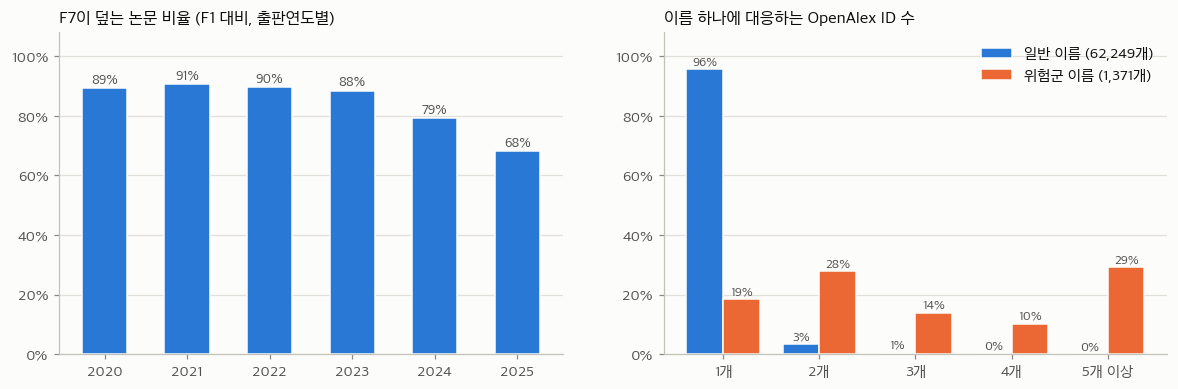

**요약**
- F7은 **2020–2025년 논문 35,594편**만 담는다(같은 기간 F1 논문의 83.1%). 포괄 비율은 2020–23년 약 90%에서 2024년 79%, 2025년 68%로 떨어진다. 2019년 이전은 전혀 없다.
- 구조는 깔끔하다. 논문당 행 수가 `n_authors`와 모두 같고, `rank + 1`이 F2의 `author_pos`와 정확히 대응한다(맞춰 본 108,370쌍에서 이름 100% 일치). 다만 `name_norm` 결측 58행과 한 논문에 같은 ID가 두 번 나오는 120행이 있다.
- **위험군 지정은 ID로 봐도 타당하다.** 일반 이름은 4.2%만 ID가 2개 이상인데, 위험군 이름은 81.4%가 2개 이상이다(중앙값 3개). 행 기준으로 "그 이름의 가장 흔한 ID에 속한 비율"은 일반 이름 96.9%, 위험군 이름 63.4%다.
- 반대 방향의 오류는 거의 없다. ID 하나에 이름이 여럿 붙는 경우는 2건뿐이다. 다만 이것은 `name_norm`이 이미 정규화된 이름이라서 그렇고, OpenAlex가 한 사람을 여러 ID로 쪼갰을 가능성(위의 "ID 2개 이상"에 섞여 있음)은 이 파일로 구분할 수 없다.
- F7은 2020년 이후만 있으므로 **2010–14 → 2020–24의 "지속 저자" 판정 자체를 ID로 검증할 수는 없다.** 지속 저자 5,065명 중 95.4%가 F7에 등장하지만, 그들의 2010–14년 논문에는 ID가 없다.

In [23]:
f7y = F1[F1.pid.isin(F7.pid)].year.value_counts().sort_index(); all20 = F1[F1.year >= 2020].year.value_counts().sort_index(); cv = f7y / all20
g7 = F7.dropna(subset=["name_norm"]).copy(); g7["risk"] = g7.name_norm.isin(RISK.name_norm)
ipn = g7.groupby(["risk", "name_norm"]).oa_id.nunique()
dist = pd.DataFrame({k: ipn[r].clip(upper=5).value_counts(normalize=True).reindex(range(1, 6), fill_value=0) for k, r in [("일반 이름", False), ("위험군 이름", True)]})
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].bar(cv.index.astype(str), cv.values, color=C["blue"], width=.55, **BAR); ax[0].set_ylim(0, 1.08); ax[0].yaxis.set_major_formatter(pct0)
for i, v in enumerate(cv.values): ax[0].text(i, v + .015, f"{v:.0%}", ha="center", color=C["ink2"], fontsize=9)
ax[0].set_title("F7이 덮는 논문 비율 (F1 대비, 출판연도별)"); ax[0].grid(axis="x", visible=False)
x = np.arange(5); wd = .38
for i, (k, c) in enumerate(zip(dist.columns, [C["blue"], C["orange"]])):
    ax[1].bar(x + (i - .5) * wd, dist[k], width=wd, color=c, label=f"{k} ({ipn[bool(i)].size:,}개)", **BAR)
    for xi, v in zip(x, dist[k]): ax[1].text(xi + (i - .5) * wd, v + .012, f"{v:.0%}", ha="center", fontsize=8.5, color=C["ink2"])
ax[1].set_xticks(x); ax[1].set_xticklabels(["1개", "2개", "3개", "4개", "5개 이상"]); ax[1].set_ylim(0, 1.08); ax[1].yaxis.set_major_formatter(pct0)
ax[1].set_title("이름 하나에 대응하는 OpenAlex ID 수"); ax[1].legend(); ax[1].grid(axis="x", visible=False)
save(fig, "F7_01_포괄범위_이름당ID수")

def purity(d):      # 이름별 최빈 ID에 속한 행의 비율
    c = d.groupby(["name_norm", "oa_id"]).size(); return c.groupby("name_norm").max().sum() / len(d)
pur = {False: purity(g7[~g7.risk]), True: purity(g7[g7.risk])}
npi = g7.groupby("oa_id").name_norm.nunique()
pos = F7.merge(F2[["pid", "author_pos", "name_norm"]].assign(rank=lambda d: d.author_pos - 1), on=["pid", "rank"], suffixes=("", "_f2"))
f7n = F7.groupby("pid").size(); cont_in = F5.name_norm.isin(g7.name_norm).mean()
check("8", "F7은 35,594편, 2020–2025년 논문만 담는다", F7.pid.nunique() == 35594 and F1.loc[F1.pid.isin(F7.pid), "year"].between(2020, 2025).all(), F7.pid.nunique())
check("8", "F7의 논문당 행 수는 F1의 n_authors와 모두 같고, rank는 0부터 빈틈없이 이어진다", (f7n == F1.set_index("pid").n_authors.reindex(f7n.index)).all() and (F7.groupby("pid")["rank"].max() + 1 == f7n).all())
check("8", "F7의 rank+1 = F2의 author_pos로 맞춘 108,370쌍에서 이름이 100% 같다", len(pos) == 108370 and (pos.name_norm == pos.name_norm_f2).all(), len(pos))
check("8", "일반 이름은 4.2%만 ID가 2개 이상인데, 위험군 이름은 81.4%가 2개 이상이다", (round((ipn[False] > 1).mean(), 3), round((ipn[True] > 1).mean(), 3)) == (.042, .814), (round((ipn[False] > 1).mean(), 4), round((ipn[True] > 1).mean(), 4)))
check("8", "ID 하나에 이름이 2개 이상 대응하는 경우는 2건뿐이다", int((npi > 1).sum()) == 2, int((npi > 1).sum()))
check("8", "F7 포괄 비율은 2020–2023년 88~91%, 2024년 79%, 2025년 68%다", cv.loc[2020:2023].between(.88, .91).all() and (round(cv[2024], 2), round(cv[2025], 2)) == (.79, .68), cv.round(3).to_dict())
md(f"""**요약**
- F7은 **2020–2025년 논문 {F7.pid.nunique():,}편**만 담는다(같은 기간 F1 논문의 {F7.pid.nunique()/all20.sum():.1%}). 포괄 비율은 2020–23년 약 {cv.loc[2020:2023].mean():.0%}에서 2024년 {cv[2024]:.0%}, 2025년 {cv[2025]:.0%}로 떨어진다. 2019년 이전은 전혀 없다.
- 구조는 깔끔하다. 논문당 행 수가 `n_authors`와 모두 같고, `rank + 1`이 F2의 `author_pos`와 정확히 대응한다(맞춰 본 {len(pos):,}쌍에서 이름 100% 일치). 다만 `name_norm` 결측 {F7.name_norm.isna().sum()}행과 한 논문에 같은 ID가 두 번 나오는 {F7.duplicated(['pid','oa_id']).sum()}행이 있다.
- **위험군 지정은 ID로 봐도 타당하다.** 일반 이름은 {(ipn[False] > 1).mean():.1%}만 ID가 2개 이상인데, 위험군 이름은 {(ipn[True] > 1).mean():.1%}가 2개 이상이다(중앙값 {ipn[True].median():.0f}개). 행 기준으로 "그 이름의 가장 흔한 ID에 속한 비율"은 일반 이름 {pur[False]:.1%}, 위험군 이름 {pur[True]:.1%}다.
- 반대 방향의 오류는 거의 없다. ID 하나에 이름이 여럿 붙는 경우는 {int((npi > 1).sum())}건뿐이다. 다만 이것은 `name_norm`이 이미 정규화된 이름이라서 그렇고, OpenAlex가 한 사람을 여러 ID로 쪼갰을 가능성(위의 "ID 2개 이상"에 섞여 있음)은 이 파일로 구분할 수 없다.
- F7은 2020년 이후만 있으므로 **2010–14 → 2020–24의 "지속 저자" 판정 자체를 ID로 검증할 수는 없다.** 지속 저자 5,065명 중 {cont_in:.1%}가 F7에 등장하지만, 그들의 2010–14년 논문에는 ID가 없다.""")

## 9. 검증 로그

위에서 건 모든 검증을 모아 보여 준다. 하나라도 실패하면 아래 `assert`에서 멈춘다.

In [24]:
LOG = pd.DataFrame(CHECKS); LOG.index = LOG.index + 1
LOG.to_csv(OUT / "01_검증로그.csv", encoding="utf-8-sig")
with pd.option_context("display.max_rows", 200, "display.max_colwidth", 140):
    display(LOG.style.map(lambda v: "color:#006300;font-weight:bold" if v is True else ("color:#d03b3b;font-weight:bold" if v is False else ""), subset=["통과"]).set_properties(**{"text-align": "left"}))
print(f"검증 {len(LOG)}건 중 통과 {int(LOG.통과.sum())}건, 실패 {int((~LOG.통과).sum())}건")
assert LOG.통과.all(), "실패한 검증:\n" + LOG[~LOG.통과].to_string()

,절,주장,관측값,통과
1,1,"결측이 있는 열은 F1의 doi_norm·topic150, F5의 coauthor_em0, F6의 top_words, F7의 name_norm뿐이다","{'F1': ['doi_norm', 'topic150'], 'F5': ['coauthor_em0'], 'F6': ['top_words'], 'F7': ['name_norm']}",True
2,1,"MANIFEST는 8개 파일을 기록하고, 8개 모두 행·열 수가 실제와 같다",8/8,True
3,1,8개 파일 모두 키가 유일하다(중복 행 없음),8/8,True
4,1,"MD5가 MANIFEST와 다른 파일은 F5, F6 두 개뿐이다","['F5_continuing_authors.csv', 'F6_topics.csv']",True
5,1,"F5, F6은 파일 앞에 BOM 3바이트를 붙이면 MANIFEST의 MD5와 같아진다(내용 변경 아님)","{'F5_continuing_authors.csv': True, 'F6_topics.csv': True}",True
6,1.1,F2.pid ⊂ F1.pid,,True
7,1.1,F2의 year·venue_short·n_authors·topic150 = F1의 같은 pid 값,,True
8,1.1,F2.name_norm ⊂ F4.name_norm,,True
9,1.1,F3.name_norm ⊂ F4.name_norm,,True
10,1.1,F5.name_norm = F4에서 continuing_main=True인 저자 집합,,True


검증 94건 중 통과 94건, 실패 0건


## 10. 종합 요약

In [25]:
md(f"""### 파일은 믿을 수 있는가
- 9개 파일은 서로 모순 없이 이어지고, 파생 파일(F3, F4의 질량, F5, F6)은 F1·F2에서 **다시 계산한 값과 정확히 같다.** 검증 {len(LOG)}건을 모두 통과했다.
- F5와 F6의 MD5가 MANIFEST와 다르지만, 원인은 BOM 3바이트 누락이고 내용은 같다. 포닥님께 "F5·F6만 BOM 없이 저장됐다"고 알려 두면 된다.

### 데이터의 분포에서 꼭 기억할 것
| # | 특성 | 수치 | 후속 분석에 주는 의미 |
|---|---|---|---|
| 1 | 최근 편중 | 2020–25년 논문이 {n2020/len(F1):.0%}, 2020–24년 논문 수는 2010–14년의 {grow:.1f}배 | 신규 저자가 많아 보이는 것은 팽창만으로도 생긴다 |
| 2 | 저널 구성 변화 | TRR {sh.TRR[1990]:.0%} → {sh.TRR[2020]:.0%}, 고정 저널 {fx[2000]:.0%} → {fx[2020]:.0%} | 주제 변화에 저널 구성 효과가 섞인다 |
| 3 | 주제 보유율의 시기 차이 | 1995–99년 {p5.주제보유율[1995]:.0%}, 2015–19년 {p5.주제보유율[2015]:.0%}, 저널별 {tv.iloc[0]:.0%}~{tv.iloc[-1]:.0%} | 오래된 기간일수록 주제 표본이 덜 대표적이다 |
| 4 | 주제와 저널의 결합 | 쇠퇴 주제 논문의 {trr_dc:.0%}가 TRR, 신생 14개 중 {n_tits}개는 1위 저널이 T-ITS | 저널을 통제하지 않으면 저널 차이가 주제 차이로 잡힌다 |
| 5 | 저자별 정보량이 작음 | 저자의 {one_p:.0%}가 논문 1편, 한 기간 주제 1개인 저자 약 {one['P20_24']:.0%} | 저자 단위 주제 분포는 잡음이 크고, 동시출현 정보는 {1-one.max():.0%}~{1-one.min():.0%}의 저자에서만 나온다 |
| 6 | 지속 저자는 소수이자 선택된 집단 | 2010–14 활동 저자의 {OVL.loc['2010–14','2020–24']:.0%}, 2020–24 질량의 {grp['질량 비중'].iloc[0]:.0%} | 지속 저자 결과를 전체 저자로 일반화할 수 없다 |
| 7 | 비중 변수의 0·1 쏠림 | `em0`의 {(F5.em0 == 0).mean():.0%}가 0, `d_em`의 {(F5.d_em == 0).mean():.0%}가 0 | 평균·선형 회귀보다 "이동 여부"와 "이동 크기"를 나눠 봐야 한다 |
| 8 | 가중치의 분모 | 저자가 전부 남은 논문 {full:.0%}, 저자 행 보존율 {covp['저자 행 보존율'].iloc[0]:.0%} → {covp['저자 행 보존율'].iloc[-1]:.0%} | `w`는 `1/n_authors`가 아니며, 최근일수록 남은 저자의 몫이 부풀려진다 |
| 9 | 인용 수의 나이 효과 | 중앙값 2015년 {cy[.5][2015]:.0f}, 2023년 {cy[.5][2023]:.0f}, 2025년 {cy[.5][2025]:.0f} | 연도 내 순위로 바꾸지 않으면 비교할 수 없다 |
| 10 | ID 검증의 범위 | F7은 2020–25년 {F7.pid.nunique():,}편, 2025년 포괄 {cv[2025]:.0%} | 2020년 이전을 포함하는 분석은 ID로 재현할 수 없다 |

### 작지만 알아 둘 이상값
- 주제 18번은 논문 {t18}편짜리 빈 주제다. 실질 주제는 149개다.
- 같은 제목 {len(dup)}행(비연구 항목 포함)이 `in_sample`에 남아 있다.
- 주제가 있는데 저자가 전원 빠져 F2에 없는 논문이 {len(lost)}편이다.
- F3의 8개 기간은 1995–2024년만 덮는다. 2025년과 1994년 이전은 F2로 직접 집계해야 한다.
- F4의 {len(zero)/len(F4):.0%}({len(zero):,}명)는 어느 기간에도 질량이 없다.
- F7에는 위험군 이름이 {n_risk_f7:,}행 남아 있다.
- VT Mag의 38번 주제에 잡지 고정 칼럼(한 저자의 단독 게재 {len(col_)}편, 질량 {topw.w.iloc[0]:.0f})이 들어 있다.

### 산출물
- 그림: `분석결과/01_EDA/figures/` ({len(list(FIG.glob('*.png')))}개)
- 표: `분석결과/01_EDA/01_파일개요.csv`, `01_검증로그.csv`""")

### 파일은 믿을 수 있는가
- 9개 파일은 서로 모순 없이 이어지고, 파생 파일(F3, F4의 질량, F5, F6)은 F1·F2에서 **다시 계산한 값과 정확히 같다.** 검증 94건을 모두 통과했다.
- F5와 F6의 MD5가 MANIFEST와 다르지만, 원인은 BOM 3바이트 누락이고 내용은 같다. 포닥님께 "F5·F6만 BOM 없이 저장됐다"고 알려 두면 된다.

### 데이터의 분포에서 꼭 기억할 것
| # | 특성 | 수치 | 후속 분석에 주는 의미 |
|---|---|---|---|
| 1 | 최근 편중 | 2020–25년 논문이 38%, 2020–24년 논문 수는 2010–14년의 2.5배 | 신규 저자가 많아 보이는 것은 팽창만으로도 생긴다 |
| 2 | 저널 구성 변화 | TRR 71% → 12%, 고정 저널 100% → 71% | 주제 변화에 저널 구성 효과가 섞인다 |
| 3 | 주제 보유율의 시기 차이 | 1995–99년 66%, 2015–19년 87%, 저널별 52%~99% | 오래된 기간일수록 주제 표본이 덜 대표적이다 |
| 4 | 주제와 저널의 결합 | 쇠퇴 주제 논문의 94%가 TRR, 신생 14개 중 7개는 1위 저널이 T-ITS | 저널을 통제하지 않으면 저널 차이가 주제 차이로 잡힌다 |
| 5 | 저자별 정보량이 작음 | 저자의 65%가 논문 1편, 한 기간 주제 1개인 저자 약 69% | 저자 단위 주제 분포는 잡음이 크고, 동시출현 정보는 25%~31%의 저자에서만 나온다 |
| 6 | 지속 저자는 소수이자 선택된 집단 | 2010–14 활동 저자의 29%, 2020–24 질량의 24% | 지속 저자 결과를 전체 저자로 일반화할 수 없다 |
| 7 | 비중 변수의 0·1 쏠림 | `em0`의 88%가 0, `d_em`의 64%가 0 | 평균·선형 회귀보다 "이동 여부"와 "이동 크기"를 나눠 봐야 한다 |
| 8 | 가중치의 분모 | 저자가 전부 남은 논문 74%, 저자 행 보존율 98% → 86% | `w`는 `1/n_authors`가 아니며, 최근일수록 남은 저자의 몫이 부풀려진다 |
| 9 | 인용 수의 나이 효과 | 중앙값 2015년 33, 2023년 16, 2025년 3 | 연도 내 순위로 바꾸지 않으면 비교할 수 없다 |
| 10 | ID 검증의 범위 | F7은 2020–25년 35,594편, 2025년 포괄 68% | 2020년 이전을 포함하는 분석은 ID로 재현할 수 없다 |

### 작지만 알아 둘 이상값
- 주제 18번은 논문 1편짜리 빈 주제다. 실질 주제는 149개다.
- 같은 제목 459행(비연구 항목 포함)이 `in_sample`에 남아 있다.
- 주제가 있는데 저자가 전원 빠져 F2에 없는 논문이 639편이다.
- F3의 8개 기간은 1995–2024년만 덮는다. 2025년과 1994년 이전은 F2로 직접 집계해야 한다.
- F4의 37%(52,581명)는 어느 기간에도 질량이 없다.
- F7에는 위험군 이름이 18,440행 남아 있다.
- VT Mag의 38번 주제에 잡지 고정 칼럼(한 저자의 단독 게재 15편, 질량 15)이 들어 있다.

### 산출물
- 그림: `분석결과/01_EDA/figures/` (17개)
- 표: `분석결과/01_EDA/01_파일개요.csv`, `01_검증로그.csv`